### **Libraries**

In [ ]:
pip install hdbscan umap-learn


In [ ]:
pip install umap-learn

In [ ]:
pip install networkx pandas numpy scipy scikit-learn GraphRicciCurvature


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.2/38.2 MB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 31.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 901.7/901.7 kB 23.4 MB/s eta 0:00:00
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.1
    Uninstalling scipy-1.16.1:
      Successfully uninstalled scipy-1.16.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tsfresh 0.21.0 requires scipy>=1.14.0; python_version >= "3.10", but you have scipy 1.13.1 which is incompatible.


In [ ]:
pip install leidenalg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 21.1 MB/s eta 0:00:00


In [ ]:
pip install graphtools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 16.2 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
import leidenalg
import igraph as ig
import plotly.graph_objects as get_ipython
from colorsys import hls_to_rgb
import plotly.graph_objects as go


## **Import data**

Load the gene interaction data, compute variance across samples for each row (interaction), sort it, and keep only the top 10% most variable edges.
(PLOT SU R)


In [ ]:
df = pd.read_csv("labeled_lioness_data.csv")
df['Row_Variance'] = df.iloc[:,2:].var(axis=1)
df_sorted = df.sort_values(by="Row_Variance", ascending = False)
top_10_percent = df_sorted.iloc[:int(len(df_sorted)*0.1)]


In [ ]:
df

,tf,gene,Sample_1,Sample_2,Sample_3,Sample_4,Sample_5,Sample_6,Sample_7,Sample_8,...,Sample_42,Sample_43,Sample_44,Sample_45,Sample_46,Sample_47,Sample_48,Sample_49,Sample_50,Row_Variance
0,ABCD1,TSPY4,3.118535,0.425735,3.478885,3.946269,4.081601,2.304871,0.332669,2.549705,...,2.992341,5.954311,2.466627,3.377258,3.744609,11.825130,6.548965,3.674585,-1.836393,5.428097
1,AFF2,TSPY4,2.477868,0.794680,3.726714,-0.078612,1.981822,-0.545429,-1.209196,2.890503,...,4.598463,2.478962,0.601810,5.895653,-0.237066,-8.132210,10.615016,-6.650433,1.715855,11.617861
2,AIFM1,TSPY4,-0.764277,2.236358,-1.521169,-1.601143,-1.946215,-0.976792,2.191357,-0.127579,...,-0.622540,-1.772317,-0.292499,-1.039424,-1.642654,-11.623132,-2.683653,-2.122135,5.018512,7.501280
3,AMELY,TSPY4,3.151135,0.300997,3.561271,3.787151,3.949151,2.031203,0.175701,2.176357,...,2.947494,5.054120,2.849812,3.175260,3.551979,12.670366,5.511750,3.417892,-1.817028,6.561474
4,AMMECR1,TSPY4,-0.562241,-2.497922,-0.683950,0.420122,0.724148,-1.938640,-2.698784,-0.889713,...,-0.685311,-0.270934,-1.043075,-0.529266,0.116916,7.402160,-1.452209,0.253068,-5.278826,4.180738
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
128876,ZNF75D,ARHGAP6,-2.491871,-2.557377,-1.668650,-1.817330,-3.927992,-3.060525,-1.153303,-3.343774,...,0.029578,-3.394217,-3.297794,-1.931714,-3.110265,-2.851937,-2.594274,-1.326171,-3.590637,0.805201
128877,ZNF81,ARHGAP6,3.902145,6.769694,5.395756,3.500334,6.369508,5.316202,6.580858,4.830704,...,4.289979,5.408933,5.846612,4.294963,4.509000,6.327082,5.701310,3.560915,4.933794,1.125033
128878,ZRSR2,ARHGAP6,4.231190,7.257740,6.482589,4.132573,5.421536,5.333749,7.202395,5.458174,...,5.742550,5.399373,5.199852,6.007216,5.094872,6.398409,5.490362,4.184571,4.915371,0.876611
128879,ZXDA,ARHGAP6,-3.768948,-6.299603,-4.106971,-3.129450,-5.776793,-4.144004,-6.017830,-4.082711,...,-3.750861,-3.864392,-3.901006,-3.876018,-4.867671,-6.354467,-4.161145,-2.689447,-5.219612,1.347569


## **Thresholds**

Define quantile thresholds to progressively remove lower variance edges. Each threshold corresponds to a sparsification level.

In [ ]:
quantile_levels = [0, 0.25, 0.5, 0.75, 0.90, 0.95, 0.97, 0.98]
quantiles = [top_10_percent['Row_Variance'].quantile(q) for q in quantile_levels]
threshold_labels = [f"Q{int(q*1000)/10}" for q in quantile_levels]

## **Leiden Clustering**

For each threshold, construct a weighted undirected graph using high-variance edges, apply Leiden clustering, and save the gene-to-cluster assignments.

In [ ]:
import random

# Seed to fix the results of clustering
random_seed = 42
random.seed(random_seed)

gene_cluster_map = {}  # {soglia_label: {gene: cluster_id}}

for i, threshold in enumerate(quantiles):
  label = threshold_labels[i]
  filtered_df = top_10_percent[top_10_percent['Row_Variance'] >= threshold]


  G_nx = nx.Graph()
  for _, row in filtered_df.iterrows():
    G_nx.add_edge(row['tf'], row['gene'], weight = row['Row_Variance'])

  edges = [(u,v, float(d['weight'])) for u,v,d in G_nx.edges(data=True)]
  G_ig = ig.Graph.TupleList(edges, edge_attrs=['weight'])

  partition = leidenalg.find_partition(G_ig, leidenalg.RBConfigurationVertexPartition, weights='weight')

  cluster_map = {}
  for cluster_id, cluster in enumerate(partition):
    for idx in cluster:
        gene = G_ig.vs[idx]['name']
        cluster_map[gene] = cluster_id
  gene_cluster_map[label] = cluster_map

In [ ]:
from IPython.display import Markdown

Markdown(r"""
The `leidenalg.RBConfigurationVertexPartition` class optimizes community structure using the Reichardt-Bornholdt (RB) configuration model, which generalizes modularity by introducing a resolution parameter $\gamma$. The algorithm aims to maximize the quality function:

$$
Q = \sum_{c}(e_{cc} - \gamma a_c^2)
$$

where $e_{cc}$ is the fraction of total edge weight within community $c$, and $a_c$ is the fraction of total edge weight connected to nodes in $c$. This allows for control over the granularity of detected communities. During optimization, Leiden improves the partition by locally moving nodes, refining disconnected components, and aggregating communities into super-nodes, repeating the process iteratively until convergence.
""")



The `leidenalg.RBConfigurationVertexPartition` class optimizes community structure using the Reichardt-Bornholdt (RB) configuration model, which generalizes modularity by introducing a resolution parameter $\gamma$. The algorithm aims to maximize the quality function:

$$
Q = \sum_{c}(e_{cc} - \gamma a_c^2)
$$

where $e_{cc}$ is the fraction of total edge weight within community $c$, and $a_c$ is the fraction of total edge weight connected to nodes in $c$. This allows for control over the granularity of detected communities. During optimization, Leiden improves the partition by locally moving nodes, refining disconnected components, and aggregating communities into super-nodes, repeating the process iteratively until convergence.


## **Labels and colors**

Generate human-readable labels for each cluster at each threshold and assign them distinct colors for visualization.

In [ ]:
  distinct_colors = [
    "rgb(230, 25, 75)",    # rosso
    "rgb(60, 180, 75)",    # verde
    "rgb(255, 225, 25)",   # giallo
    "rgb(0, 130, 200)",    # blu
    "rgb(245, 130, 48)",   # arancione
    "rgb(145, 30, 180)",   # viola
    "rgb(70, 240, 240)",   # ciano
    "rgb(240, 50, 230)",   # rosa
    "rgb(210, 245, 60)",   # lime
    "rgb(250, 190, 190)",  # rosa chiaro
    "rgb(0, 128, 128)",    # teal
    "rgb(230, 190, 255)",  # lilla chiaro
    "rgb(170, 110, 40)",   # marrone
    "rgb(255, 250, 200)",  # giallo chiaro
    "rgb(128, 0, 0)",      # bordeaux
    "rgb(170, 255, 195)",  # verde chiaro
    "rgb(0, 0, 128)",      # blu scuro
    "rgb(128, 128, 0)",    # oliva
    "rgb(255, 215, 180)",  # pesca
    "rgb(128, 64, 0)",     # marrone scuro
    "rgb(255, 100, 255)"   # magenta
]

In [ ]:
labels = []
label_index = {}
cluster_colors = {}
idx = 0
color_idx = 0

for thresh in threshold_labels:
  clusters = sorted(set(gene_cluster_map[thresh].values()))
  for cluster_id in clusters:
    label = f"{thresh}_C{cluster_id}"
    labels.append(label)
    label_index[(thresh, cluster_id)] = idx
    cluster_colors[(thresh, cluster_id)] = distinct_colors[color_idx % len(distinct_colors)]
    idx +=1
    color_idx +=1

Track gene transitions between clusters across successive thresholds to define Sankey flow paths.

In [ ]:
sources, targets, values, link_colors = [],[],[],[]

for i in range(len(threshold_labels) - 1):
  t1, t2 = threshold_labels[i], threshold_labels[i+1]
  m1, m2 = gene_cluster_map[t1], gene_cluster_map[t2]

  for gene in set(m1.keys()).intersection(m2.keys()):
    c1, c2 = m1[gene], m2[gene]
    src_idx = label_index[(t1,c1)]
    tgt_idx = label_index[(t2,c2)]

    sources.append(src_idx)
    targets.append(tgt_idx)
    values.append(1)

    rgb = cluster_colors[(t1,c1)]
    rgba = rgb.replace("rgb", "rgba").replace(")", ", 0.4)")
    link_colors.append(rgba)

## **Sankey Plot**

Visualize how genes move across clusters through thresholds using a Sankey plot, where nodes are cluster labels and flows represent shared genes.

In [ ]:
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=15,
        thickness=20,
        label=labels,
        line=dict(color="black", width=0.5),
        color=[cluster_colors[(thresh, cid)] for thresh, cid in label_index]  # fix qui
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color=link_colors
    )
)])


fig.update_layout(
    title_text="Cluster Evolution",
    font_size=12,
    width=1200,
    height=800,
    plot_bgcolor="white",
    title_x=0.5
)

fig.show()

***Sistemo etichette***

In [ ]:
import plotly.graph_objects as go

# Colori distinti per cluster
distinct_colors = [
    "rgb(230, 25, 75)",    # rosso
    "rgb(60, 180, 75)",    # verde
    "rgb(255, 225, 25)",   # giallo
    "rgb(0, 130, 200)",    # blu
    "rgb(245, 130, 48)",   # arancione
    "rgb(145, 30, 180)",   # viola
    "rgb(70, 240, 240)",   # ciano
    "rgb(240, 50, 230)",   # rosa
    "rgb(210, 245, 60)",   # lime
    "rgb(250, 190, 190)",  # rosa chiaro
    "rgb(0, 128, 128)",    # teal
    "rgb(230, 190, 255)",  # lilla chiaro
    "rgb(170, 110, 40)",   # marrone
    "rgb(255, 250, 200)",  # giallo chiaro
    "rgb(128, 0, 0)",      # bordeaux
    "rgb(170, 255, 195)",  # verde chiaro
    "rgb(0, 0, 128)",      # blu scuro
    "rgb(128, 128, 0)",    # oliva
    "rgb(255, 215, 180)",  # pesca
    "rgb(128, 64, 0)",     # marrone scuro
    "rgb(255, 100, 255)"   # magenta
]

# Inizializzazione
labels = []
label_index = {}
cluster_colors = {}
idx = 0
color_idx = 0

# Costruisci etichette con formato Q0.25_C0
for thresh in threshold_labels:
    clusters = sorted(set(gene_cluster_map[thresh].values()))
    thresh_float = float(str(thresh).replace("Q", "")) / 100
    for cluster_id in clusters:
        label = f"Q{thresh_float:.2f}_C{cluster_id}"
        labels.append(label)
        label_index[(thresh, cluster_id)] = idx
        cluster_colors[(thresh, cluster_id)] = distinct_colors[color_idx % len(distinct_colors)]
        idx += 1
        color_idx += 1

# Traccia transizioni tra soglie
sources, targets, values, link_colors = [], [], [], []

for i in range(len(threshold_labels) - 1):
    t1, t2 = threshold_labels[i], threshold_labels[i + 1]
    m1, m2 = gene_cluster_map[t1], gene_cluster_map[t2]

    for gene in set(m1.keys()).intersection(m2.keys()):
        c1, c2 = m1[gene], m2[gene]
        src_idx = label_index[(t1, c1)]
        tgt_idx = label_index[(t2, c2)]

        sources.append(src_idx)
        targets.append(tgt_idx)
        values.append(1)

        rgb = cluster_colors[(t1, c1)]
        rgba = rgb.replace("rgb", "rgba").replace(")", ", 0.4)")
        link_colors.append(rgba)

# Crea Sankey Plot
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=15,
        thickness=20,
        label=labels,
        line=dict(color="black", width=0.5),
        color=[cluster_colors[(thresh, cid)] for thresh, cid in label_index]
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color=link_colors
    )
)])

fig.update_layout(
    title_text="Cluster Evolution Across Thresholds",
    font_size=12,
    width=1200,
    height=800,
    plot_bgcolor="white",
    title_x=0.5
)

fig.show()


*A Sankey plot combined with Leiden clustering on a graph of variances G is an effective tool for identifying "hotzones" in complex data networks. Initially, the graph includes all edges, even those with low variance, meaning that it represents a broad, unrefined network. As the graph is sparsified by gradually removing edges with low variance, it becomes increasingly focused on the most variable interactions — those edges that have a high degree of fluctuation or change. This filtering process allows the graph to highlight key nodes and clusters where variability is most pronounced, revealing areas of the network (referred to as "hotzones") that exhibit dynamic behavior or unusual patterns.*

*Leiden clustering, applied after the sparsification, groups nodes into communities based on the strength and similarity of their interactions, but with a particular emphasis on the most variable connections. By leveraging both the variance of edges and the clustering approach, this method provides a more nuanced and targeted view of the network, helping to uncover regions of the graph that may be driving key biological or systemic processes.*

Compute average variance of edges connected to genes in each cluster at each threshold. High values indicate dynamic activity ("hotness")

In [ ]:
from collections import defaultdict

# Compute the average variance for each cluster at each threshold
cluster_variances = defaultdict(dict)

for threshold in threshold_labels:
    # Mappa gene-cluster for this threshold
    gene_cluster_map_for_threshold = gene_cluster_map[threshold]

    # For each cluster
    for cluster_id in set(gene_cluster_map_for_threshold.values()):
        # Find the genes in the cluster
        genes_in_cluster = [gene for gene, assigned_cluster in gene_cluster_map_for_threshold.items() if assigned_cluster == cluster_id]

        # ATTENZIONE: bisogna cercare sia 'tf' che 'gene' nelle colonne!
        # Perché il grafo è costruito su 'tf' e 'gene', non solo su 'gene'.
        mask = top_10_percent['tf'].isin(genes_in_cluster) | top_10_percent['gene'].isin(genes_in_cluster)
        cluster_variance_values = top_10_percent[mask]['Row_Variance']


        mean_variance = cluster_variance_values.mean() if not cluster_variance_values.empty else 0


        cluster_variances[threshold][cluster_id] = mean_variance

# Print the results
for threshold in threshold_labels:
    print(f"\n🔸 Threshold {threshold}:")
    for cluster_id, mean_variance in cluster_variances[threshold].items():
        print(f"  Cluster {cluster_id}: Mean Variance = {mean_variance:.4f}")



🔸 Threshold Q0.0:
  Cluster 0: Mean Variance = 109.7916
  Cluster 1: Mean Variance = 96.1863
  Cluster 2: Mean Variance = 155.5454

🔸 Threshold Q25.0:
  Cluster 0: Mean Variance = 112.8079
  Cluster 1: Mean Variance = 94.8115
  Cluster 2: Mean Variance = 117.5959

🔸 Threshold Q50.0:
  Cluster 0: Mean Variance = 107.5773
  Cluster 1: Mean Variance = 103.1088

🔸 Threshold Q75.0:
  Cluster 0: Mean Variance = 115.8376
  Cluster 1: Mean Variance = 106.9565
  Cluster 2: Mean Variance = 103.9214

🔸 Threshold Q90.0:
  Cluster 0: Mean Variance = 139.0670
  Cluster 1: Mean Variance = 142.4259
  Cluster 2: Mean Variance = 159.1644
  Cluster 3: Mean Variance = 147.5353

🔸 Threshold Q95.0:
  Cluster 0: Mean Variance = 128.6144
  Cluster 1: Mean Variance = 168.9475

🔸 Threshold Q97.0:
  Cluster 0: Mean Variance = 149.6944
  Cluster 1: Mean Variance = 140.1615
  Cluster 2: Mean Variance = 156.5257
  Cluster 3: Mean Variance = 308.4748

🔸 Threshold Q98.0:
  Cluster 0: Mean Variance = 162.2929
  Clust

**Fiedler Value**

Calculate the Fiedler value for each cluster, which quantifies how structurally connected the cluster is. Higher values mean better internal cohesion

In [ ]:
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigvalsh

fiedler_values = defaultdict(dict)  # Dictionary to store Fiedler values for each cluster at each threshold

for threshold in threshold_labels:
    # Get the gene-to-cluster mapping at the current threshold
    gene_cluster_map_for_threshold = gene_cluster_map[threshold]

    # Filter the data to include only edges with Row_Variance above the current threshold
    filtered_df = top_10_percent[
        (top_10_percent['Row_Variance'] >= quantiles[threshold_labels.index(threshold)])
    ]

    for cluster_id in set(gene_cluster_map_for_threshold.values()):
        # Get all genes assigned to the current cluster
        cluster_genes = [gene for gene, cid in gene_cluster_map_for_threshold.items() if cid == cluster_id]

        # Extract only the edges where both source and target genes are in the current cluster
        cluster_edges = filtered_df[
            filtered_df['tf'].isin(cluster_genes) & filtered_df['gene'].isin(cluster_genes)
        ]

        # If the cluster is too small (less than 2 edges), assign Fiedler value = 0
        if len(cluster_edges) < 2:
            fiedler_values[threshold][cluster_id] = 0
            continue

        # Build the subgraph for the current cluster
        G_sub = nx.Graph()
        for _, row in cluster_edges.iterrows():
            G_sub.add_edge(row['tf'], row['gene'], weight=row['Row_Variance'])

        # Create the weighted adjacency matrix
        A = nx.to_numpy_array(G_sub, weight='weight')

        # Compute the normalized Laplacian matrix
        L = laplacian(A, normed=True)

        # Compute the eigenvalues of the Laplacian matrix
        eigenvalues = eigvalsh(L)

        # The Fiedler value is the second smallest eigenvalue (index 1)
        fiedler = eigenvalues[1] if len(eigenvalues) > 1 else 0
        fiedler_values[threshold][cluster_id] = fiedler


In [ ]:
for threshold in threshold_labels:
    print(f"\n🔸 Threshold {threshold}:")
    for cluster_id, f_value in fiedler_values[threshold].items():
        print(f"  Cluster {cluster_id}: Fiedler value = {f_value:.4f}")



🔸 Threshold Q0.0:
  Cluster 0: Fiedler value = 0.9439
  Cluster 1: Fiedler value = 0.9041
  Cluster 2: Fiedler value = 0.5442

🔸 Threshold Q25.0:
  Cluster 0: Fiedler value = 0.9364
  Cluster 1: Fiedler value = 0.8427
  Cluster 2: Fiedler value = 0.6911

🔸 Threshold Q50.0:
  Cluster 0: Fiedler value = 0.8701
  Cluster 1: Fiedler value = 0.8995

🔸 Threshold Q75.0:
  Cluster 0: Fiedler value = 0.7867
  Cluster 1: Fiedler value = 0.7743
  Cluster 2: Fiedler value = 0.9211

🔸 Threshold Q90.0:
  Cluster 0: Fiedler value = 0.8970
  Cluster 1: Fiedler value = 0.9791
  Cluster 2: Fiedler value = 1.0000
  Cluster 3: Fiedler value = 1.0000

🔸 Threshold Q95.0:
  Cluster 0: Fiedler value = 0.8816
  Cluster 1: Fiedler value = 0.6825

🔸 Threshold Q97.0:
  Cluster 0: Fiedler value = 1.0000
  Cluster 1: Fiedler value = 1.0000
  Cluster 2: Fiedler value = 1.0000
  Cluster 3: Fiedler value = 0.3720

🔸 Threshold Q98.0:
  Cluster 0: Fiedler value = 1.0000
  Cluster 1: Fiedler value = 1.0000
  Cluster 2: 

The **Fiedler value** measures the **internal connectivity** of a cluster within a graph. A high Fiedler value (close to 1) indicates that the cluster is tightly connected and structurally cohesive, while a low value suggests weaker internal links or a more fragmented structure. Tracking Fiedler values across thresholds reveals how robust or stable clusters are as the network becomes sparser.


This pipeline identifies "hotzones" in a gene interaction network by combining:

* Edge variance filtering to isolate dynamic interactions.
* Leiden clustering to group strongly interacting genes.
* Sankey plots to track cluster evolution.
* Mean variance as a measure of biological "activity" within clusters.
* Fiedler values to evaluate structural integrity of each cluster.

By selecting clusters that are both high variance and well-connected, the approach isolates stable and dynamic regions of the network likely relevant for further biological investigation.

## **Extract the HotZone genes**

**1) ALL TOGETHER**

In [ ]:
threshold_to_extract = 'Q98.0'

all_genes = list(gene_cluster_map[threshold_to_extract].keys())

print(f"All genes at threshold {threshold_to_extract}:")
print(all_genes)
print(f"Total genes: {len(all_genes)}")


All genes at threshold Q98.0:
['MAGED1', 'AIFM1', 'MAOB', 'TMSB15A', 'GRIA3', 'MAP3K15', 'NDUFB11', 'ARHGAP6', 'GAGE12G', 'ZC3H12B', 'GAGE12D', 'RBM10', 'BEX5', 'RPS4Y1', 'ARSD', 'PCDH11Y', 'PDZD4', 'KIAA1210', 'RAI2', 'PAGE2B', 'FRMPD4', 'RAB41', 'FTHL17', 'KDM6A', 'ATRX', 'ARHGEF9', 'UTY', 'NDUFA1', 'IRAK1', 'IGBP1', 'ZMAT1', 'PIGA', 'RBMY1D', 'CSAG1', 'DMD', 'NLGN4X', 'SH3KBP1', 'TMSB4X', 'PPEF1', 'MSL3', 'ZNF630', 'SASH3', 'GPM6B', 'TAF7L', 'ZFY', 'MID1IP1', 'SLC38A5', 'SLC25A14', 'ARHGAP4', 'ARHGEF6', 'KIF4A', 'HSD17B10', 'TFE3', 'NLGN3', 'PAK3', 'BTK', 'TSPAN6', 'KLHL34', 'APOOL', 'MAMLD1', 'TAF9B', 'CSTF2', 'PFKFB1', 'SLC6A8', 'GABRQ', 'PCDH19', 'MBTPS2', 'MAGIX', 'CDK16', 'HS6ST2', 'DDX3X', 'UPRT', 'RAP2C', 'NUDT10', 'FAM9B', 'GAGE12B', 'ZRSR2', 'CNKSR2', 'GAGE12H', 'ZNF449', 'AP1S2', 'ZNF81', 'AMOT', 'SLC25A43', 'BCORL1', 'SCML1', 'SLC25A5', 'CXorf38', 'TSPY1', 'CLCN5', 'NHS', 'NAP1L3', 'PDZD11', 'ZXDA', 'NLGN4Y', 'CITED1', 'UBQLN2', 'ARMCX2', 'RPL10', 'TBL1X', 'RIBC1', 'CHIC1

In [ ]:
filtered_df = df[df['tf'].isin(all_genes) & df['gene'].isin(all_genes)]
filtered_df

,tf,gene,Sample_1,Sample_2,Sample_3,Sample_4,Sample_5,Sample_6,Sample_7,Sample_8,...,Sample_42,Sample_43,Sample_44,Sample_45,Sample_46,Sample_47,Sample_48,Sample_49,Sample_50,Row_Variance
1437,AFF2,PCDH11Y,-3.823800,0.274878,-5.975964,-0.122896,-3.550411,-0.254009,3.712125,-6.392849,...,-7.709454,-5.062950,-1.934617,-9.863098,0.934978,10.413186,-14.429083,11.549497,-0.895402,37.302398
1438,AIFM1,PCDH11Y,4.550390,6.939310,5.262910,3.470822,3.158394,4.829010,6.864064,4.993612,...,4.259091,4.532846,5.052922,5.231005,6.629819,7.291920,4.717943,5.878468,3.460698,1.541097
1441,AMOT,PCDH11Y,5.032013,6.772230,6.317274,4.539820,4.422478,5.072354,6.774531,5.911761,...,5.393000,5.063623,4.847803,6.077821,5.719351,6.545418,5.629776,5.476925,4.687925,0.515249
1442,AP1S2,PCDH11Y,4.730979,6.281401,4.110611,3.458172,3.054165,5.220190,5.820357,5.459722,...,3.661475,5.699990,3.389536,4.330135,6.286497,6.623339,5.258354,6.059470,3.042480,1.415035
1445,APOOL,PCDH11Y,-0.500162,13.195315,-2.497965,-1.781141,-1.662874,3.184926,2.146683,4.316566,...,-1.252844,9.518030,0.605693,-5.009425,-4.979824,-15.633722,15.398379,-0.049821,-2.259487,39.259680
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
128873,ZNF449,ARHGAP6,4.754085,5.976650,5.590506,4.254038,5.181681,5.735460,7.181166,4.961595,...,5.682279,6.451096,5.536431,4.974648,5.530314,6.750249,6.016199,4.478013,6.197411,1.010411
128874,ZNF630,ARHGAP6,-3.819820,-6.167513,-3.776926,-3.051421,-5.535428,-3.942833,-5.589027,-4.612117,...,-3.686967,-3.577675,-4.594965,-3.723477,-4.691459,-6.061626,-4.026188,-2.536798,-5.438611,1.283158
128877,ZNF81,ARHGAP6,3.902145,6.769694,5.395756,3.500334,6.369508,5.316202,6.580858,4.830704,...,4.289979,5.408933,5.846612,4.294963,4.509000,6.327082,5.701310,3.560915,4.933794,1.125033
128878,ZRSR2,ARHGAP6,4.231190,7.257740,6.482589,4.132573,5.421536,5.333749,7.202395,5.458174,...,5.742550,5.399373,5.199852,6.007216,5.094872,6.398409,5.490362,4.184571,4.915371,0.876611


In [ ]:
# Salvataggio in un file CSV
filtered_df.to_csv('filtered_df.csv', index=False)

## **Using HotZones Genes**

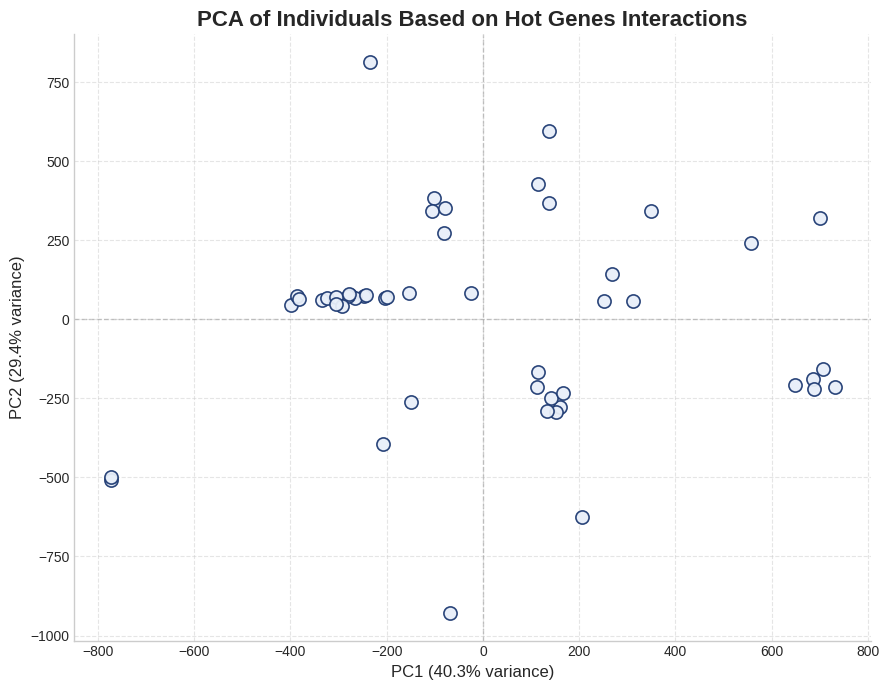

In [ ]:
# --- Imports ---
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# --- Prepara i dati (usa filtered_df già in memoria) ---
# Tieni solo le colonne numeriche (escludi meta-info)
data_values = filtered_df.drop(columns=["tf", "gene", "Row_Variance"])

# Trasponi: righe = individui
data_indiv = data_values.T
data_indiv.index.name = "Individual"

# --- PCA (2 componenti per visualizzazione) ---
pca = PCA(n_components=2)
pca_result = pca.fit_transform(data_indiv)

# Percentuali di varianza per le etichette assi
pc1_var = pca.explained_variance_ratio_[0] * 100
pc2_var = pca.explained_variance_ratio_[1] * 100

# --- Plot elegante, centro chiaro + bordo scuro ---
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    pca_result[:, 0], pca_result[:, 1],
    s=90,
    facecolors="#e8eff9",   # centro chiaro
    edgecolors="#1f3b73",   # bordo blu scuro
    linewidths=1.2,
    alpha=0.95
)

# Croci di riferimento sugli assi
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.4)
ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.4)

# Titolo e assi
ax.set_title("PCA of Individuals Based on Hot Genes Interactions",
             fontsize=16, weight="bold")
ax.set_xlabel(f"PC1 ({pc1_var:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({pc2_var:.1f}% variance)", fontsize=12)

# Griglia discreta + pulizia spines
ax.grid(True, linestyle="--", alpha=0.5)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


**Now do clustering**

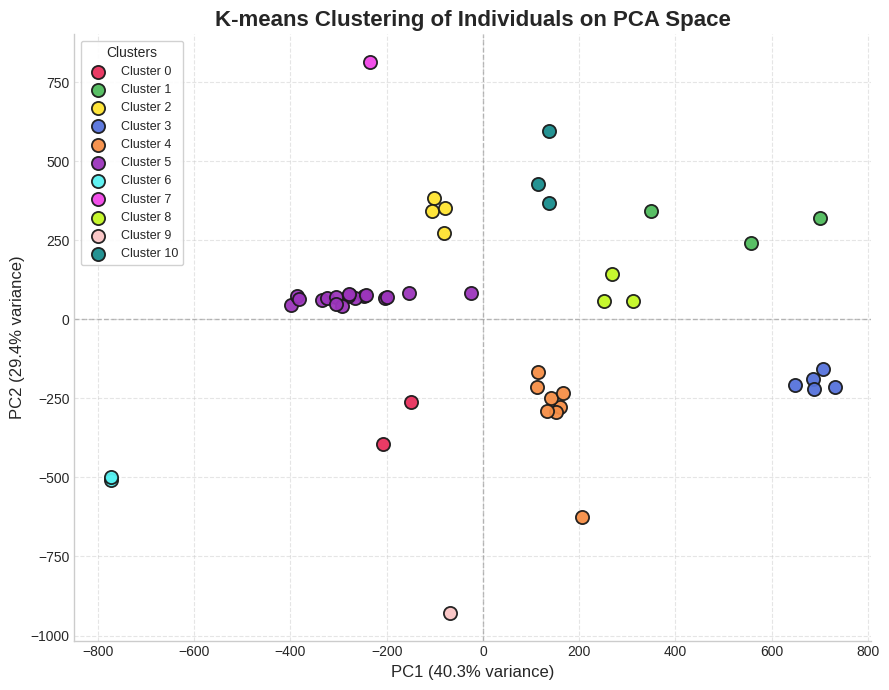

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
import numpy as np

# --- KMeans ---
n_clusters = 11
kmeans_hot = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
cluster_labels_hot = kmeans_hot.fit_predict(pca_result)

# --- Palette (i tuoi colori di base) ---
base_palette = [
    "#e6194b",  # rosso vivo
    "#3cb44b",  # verde acceso
    "#ffe119",  # giallo brillante
    "#4363d8",  # blu intenso
    "#f58231",  # arancione forte
    "#911eb4",  # viola vivace
    "#46f0f0",  # ciano brillante
    "#f032e6",  # rosa acceso
    "#bcf60c",  # lime elettrico
    "#fabebe",  # rosa chiaro
    "#008080"   # teal profondo
]

# Funzione per schiarire i colori (blend verso bianco)
def lighten(hex_color, factor=0.85):
    rgb = np.array(mcolors.to_rgb(hex_color))
    return mcolors.to_hex(1 - factor * (1 - rgb))

face_colors = [lighten(c, 0.9) for c in base_palette[:n_clusters]]
edge_colors = ["#1a1a1a"] * n_clusters   # contorno scuro uniforme

# --- Stile coerente col PCA precedente ---
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))

# Scatter per cluster: centro chiaro, bordo scuro
for k in range(n_clusters):
    mask = (cluster_labels_hot == k)
    ax.scatter(
        pca_result[mask, 0], pca_result[mask, 1],
        s=90,
        facecolors=face_colors[k],
        edgecolors=edge_colors[k],
        linewidths=1.3,
        alpha=0.95,
        label=f"Cluster {k}"
    )

# Griglia e assi
ax.grid(True, linestyle="--", alpha=0.5)
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.5)

# Titolo e assi
ax.set_title("K-means Clustering of Individuals on PCA Space", fontsize=16, weight="bold")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)", fontsize=12)

# Legenda
leg = ax.legend(frameon=True, title="Clusters", fontsize=9)
leg.get_frame().set_alpha(0.9)

# Pulizia spines
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import silhouette_score

score = silhouette_score(pca_result, cluster_labels_hot)
print(f"Silhouette Score: {score:.2f}")


Silhouette Score: 0.64


In [ ]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

print("Calinski-Harabasz:", calinski_harabasz_score(pca_result, cluster_labels_hot))
print("Davies-Bouldin:", davies_bouldin_score(pca_result, cluster_labels_hot))  # più basso è meglio


Calinski-Harabasz: 104.30470679754517
Davies-Bouldin: 0.38329789516857954


**Select the best n**

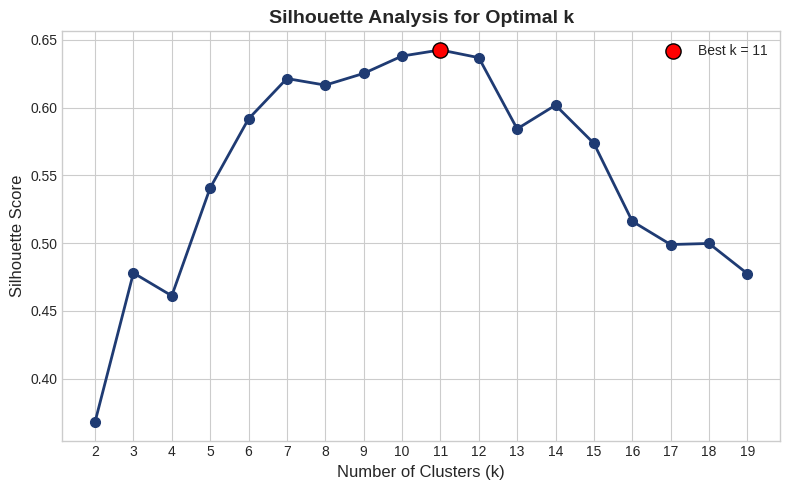

In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

silhouette_scores = []
K_range = range(2, 20)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(pca_result)
    score = silhouette_score(pca_result, labels)
    silhouette_scores.append(score)

# Trova il massimo
best_k = K_range[silhouette_scores.index(max(silhouette_scores))]
best_score = max(silhouette_scores)

# Stile elegante
plt.style.use("seaborn-v0_8-whitegrid")

# Plot linea
plt.figure(figsize=(8, 5))
plt.plot(
    K_range,
    silhouette_scores,
    marker="o",
    markersize=7,
    linewidth=2,
    color="#1f3b73",   # blu scuro
)

# Evidenzia il punto migliore
plt.scatter(
    best_k,
    best_score,
    color="red",
    s=120,              # dimensione marker
    edgecolor="black",
    zorder=5,
    label=f"Best k = {best_k}"
)

# Impostazioni asse x: solo numeri interi
plt.xticks(K_range)

# Label e titolo
plt.xlabel("Number of Clusters (k)", fontsize=12)
plt.ylabel("Silhouette Score", fontsize=12)
plt.title("Silhouette Analysis for Optimal k", fontsize=14, weight="bold")

# Legenda
plt.legend()

plt.tight_layout()
plt.show()


## **Using all the genes**

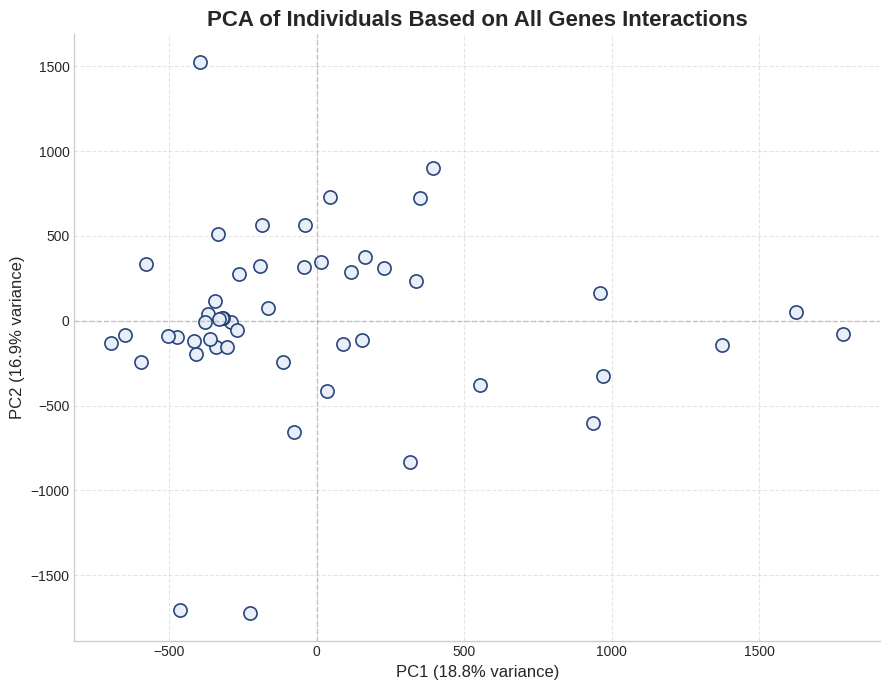

In [ ]:
# --- Imports ---
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# --- Prepara i dati (usa filtered_df già in memoria) ---
# Tieni solo le colonne numeriche (escludi meta-info)
# Extract only the numerical values (Sample_1...Sample_50)
data_values = df.drop(columns=["tf", "gene", "Row_Variance"])

# Transpose the data so that individuals are rows
data_indiv = data_values.T
data_indiv.index.name = "Individual"

# Perform PCA (reducing to 2 components for visualization)
pca = PCA(n_components=2)
pca_result = pca.fit_transform(data_indiv)

# Percentuali di varianza per le etichette assi
pc1_var = pca.explained_variance_ratio_[0] * 100
pc2_var = pca.explained_variance_ratio_[1] * 100

# --- Plot elegante, centro chiaro + bordo scuro ---
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    pca_result[:, 0], pca_result[:, 1],
    s=90,
    facecolors="#e8eff9",   # centro chiaro
    edgecolors="#1f3b73",   # bordo blu scuro
    linewidths=1.2,
    alpha=0.95
)

# Croci di riferimento sugli assi
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.4)
ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.4)

# Titolo e assi
ax.set_title("PCA of Individuals Based on All Genes Interactions",
             fontsize=16, weight="bold")
ax.set_xlabel(f"PC1 ({pc1_var:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({pc2_var:.1f}% variance)", fontsize=12)

# Griglia discreta + pulizia spines
ax.grid(True, linestyle="--", alpha=0.5)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


**Now do clustering**

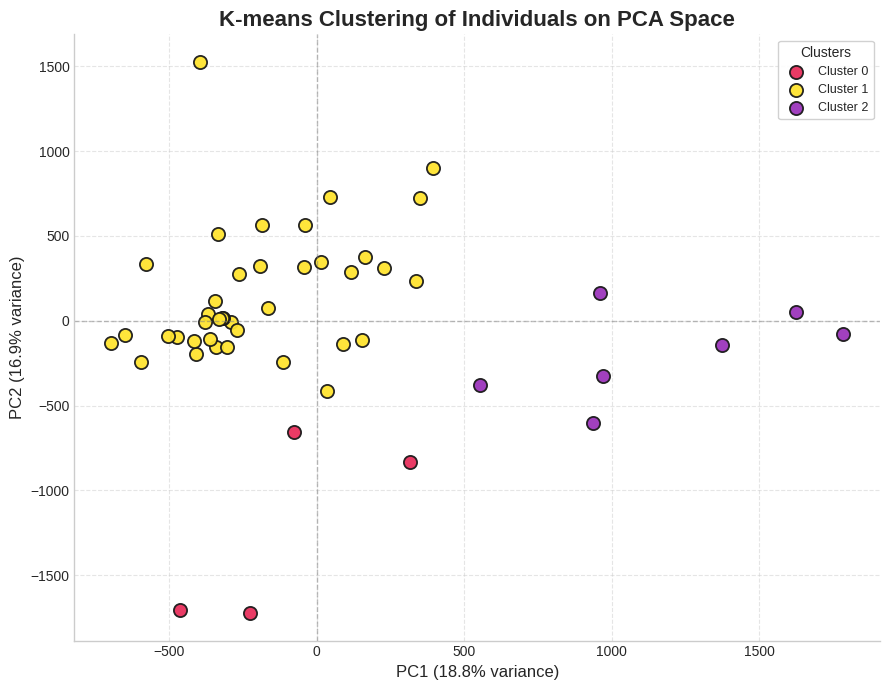

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
import numpy as np

# --- KMeans ---
n_clusters = 3
kmeans_all = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
cluster_labels_all = kmeans_all.fit_predict(pca_result)

# --- Palette (i tuoi colori di base) ---
base_palette = [
    "#e6194b",  # rosso vivo
    "#ffe119",  # giallo brillante
    "#911eb4",  # viola vivace
]

# Funzione per schiarire i colori (blend verso bianco)
def lighten(hex_color, factor=0.85):
    rgb = np.array(mcolors.to_rgb(hex_color))
    return mcolors.to_hex(1 - factor * (1 - rgb))

face_colors = [lighten(c, 0.9) for c in base_palette[:n_clusters]]
edge_colors = ["#1a1a1a"] * n_clusters   # contorno scuro uniforme

# --- Stile coerente col PCA precedente ---
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))

# Scatter per cluster: centro chiaro, bordo scuro
for k in range(n_clusters):
    mask = (cluster_labels_all == k)
    ax.scatter(
        pca_result[mask, 0], pca_result[mask, 1],
        s=90,
        facecolors=face_colors[k],
        edgecolors=edge_colors[k],
        linewidths=1.3,
        alpha=0.95,
        label=f"Cluster {k}"
    )

# Griglia e assi
ax.grid(True, linestyle="--", alpha=0.5)
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.5)

# Titolo e assi
ax.set_title("K-means Clustering of Individuals on PCA Space", fontsize=16, weight="bold")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)", fontsize=12)

# Legenda
leg = ax.legend(frameon=True, title="Clusters", fontsize=9)
leg.get_frame().set_alpha(0.9)

# Pulizia spines
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


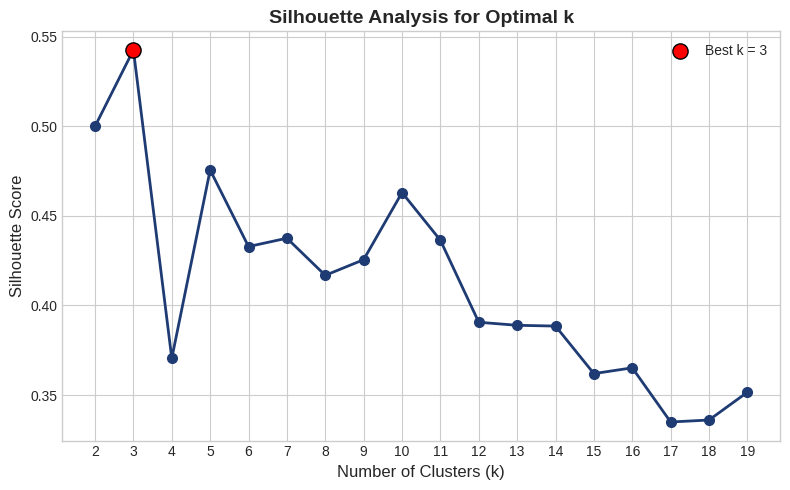

In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

silhouette_scores = []
K_range = range(2, 20)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(pca_result)
    score = silhouette_score(pca_result, labels)
    silhouette_scores.append(score)

# Trova il massimo
best_k = K_range[silhouette_scores.index(max(silhouette_scores))]
best_score = max(silhouette_scores)

# Stile elegante
plt.style.use("seaborn-v0_8-whitegrid")

# Plot linea
plt.figure(figsize=(8, 5))
plt.plot(
    K_range,
    silhouette_scores,
    marker="o",
    markersize=7,
    linewidth=2,
    color="#1f3b73",   # blu scuro
)

# Evidenzia il punto migliore
plt.scatter(
    best_k,
    best_score,
    color="red",
    s=120,              # dimensione marker
    edgecolor="black",
    zorder=5,
    label=f"Best k = {best_k}"
)

# Impostazioni asse x: solo numeri interi
plt.xticks(K_range)

# Label e titolo
plt.xlabel("Number of Clusters (k)", fontsize=12)
plt.ylabel("Silhouette Score", fontsize=12)
plt.title("Silhouette Analysis for Optimal k", fontsize=14, weight="bold")

# Legenda
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import silhouette_score

score = silhouette_score(pca_result, cluster_labels_all)
print(f"Silhouette Score: {score:.2f}")


Silhouette Score: 0.54


In [ ]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

print("Calinski-Harabasz:", calinski_harabasz_score(pca_result, cluster_labels_all))
print("Davies-Bouldin:", davies_bouldin_score(pca_result, cluster_labels_all))  # più basso è meglio


Calinski-Harabasz: 38.284611960188506
Davies-Bouldin: 0.6650991351824359


## **Using genes in each community**

**2) GENES IN EACH COMMUNITY**

* Community 0

In [ ]:
threshold_to_extract = 'Q98.0'
cluster_to_extract = 0


genes_98_0 = [
    gene for gene, cluster_id in gene_cluster_map[threshold_to_extract].items()
    if cluster_id == cluster_to_extract
]

print(f"Genes at the threshold {threshold_to_extract}, cluster {cluster_to_extract}:")
print(genes_98_0)

len(genes_98_0)

Genes at the threshold Q98.0, cluster 0:
['MAGED1', 'AIFM1', 'MAOB', 'TMSB15A', 'GRIA3', 'MAP3K15', 'NDUFB11', 'ARHGAP6', 'GAGE12G', 'ZC3H12B', 'GAGE12D', 'RBM10', 'BEX5', 'RPS4Y1', 'ARSD', 'PCDH11Y', 'PDZD4', 'KIAA1210', 'RAI2', 'PAGE2B', 'FRMPD4', 'RAB41', 'FTHL17', 'KDM6A', 'ATRX', 'ARHGEF9', 'UTY', 'NDUFA1', 'IRAK1', 'IGBP1', 'ZMAT1', 'PIGA', 'RBMY1D', 'CSAG1', 'DMD', 'NLGN4X', 'SH3KBP1', 'TMSB4X', 'PPEF1', 'MSL3', 'ZNF630', 'SASH3', 'GPM6B', 'TAF7L', 'ZFY', 'MID1IP1', 'SLC38A5', 'SLC25A14', 'ARHGAP4', 'ARHGEF6', 'KIF4A', 'HSD17B10', 'TFE3', 'NLGN3', 'PAK3', 'BTK', 'TSPAN6', 'KLHL34']


58

In [ ]:
df = pd.read_csv("labeled_lioness_data.csv")

In [ ]:
filtered_df_0 = df[df['tf'].isin(genes_98_0) & df['gene'].isin(genes_98_0)]
filtered_df_0

,tf,gene,Sample_1,Sample_2,Sample_3,Sample_4,Sample_5,Sample_6,Sample_7,Sample_8,...,Sample_41,Sample_42,Sample_43,Sample_44,Sample_45,Sample_46,Sample_47,Sample_48,Sample_49,Sample_50
1438,AIFM1,PCDH11Y,4.550390,6.939310,5.262910,3.470822,3.158394,4.829010,6.864064,4.993612,...,4.814903,4.259091,4.532846,5.052922,5.231005,6.629819,7.291920,4.717943,5.878468,3.460698
1447,ARHGAP4,PCDH11Y,1.596073,3.641536,1.672743,0.076833,-0.087429,0.807796,3.243106,1.988530,...,0.741749,1.680872,1.321380,2.380630,2.076828,2.466069,3.857283,1.465621,2.049993,0.736806
1448,ARHGAP6,PCDH11Y,4.718327,7.055911,5.705408,4.024321,3.464717,5.124964,6.823160,6.357502,...,3.976686,5.416451,6.565804,4.574515,6.322977,6.474346,6.830265,6.221217,5.058906,4.101832
1449,ARHGEF6,PCDH11Y,-3.843810,-5.859292,-4.261915,-3.010244,-2.690738,-4.220364,-5.674487,-4.852100,...,-3.474089,-3.841102,-5.312251,-3.853844,-4.719951,-5.610707,-6.428706,-5.234349,-4.480729,-3.051726
1450,ARHGEF9,PCDH11Y,-3.917492,-6.184264,-4.047240,-2.667277,-2.394134,-4.329276,-5.526395,-4.313554,...,-3.350797,-3.655885,-4.753519,-3.656141,-4.290874,-5.386972,-5.341746,-4.898498,-4.823065,-2.951651
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
128849,UTY,ARHGAP6,-4.115802,-5.882976,-4.100084,-3.224549,-6.071500,-4.421567,-5.650381,-4.184789,...,-4.181949,-3.653488,-4.768957,-3.810825,-4.500261,-5.686288,-6.568236,-5.089014,-2.827765,-5.769306
128860,ZC3H12B,ARHGAP6,4.311069,6.589686,3.765689,3.096904,7.386324,5.261288,6.239342,4.542777,...,4.564205,3.865920,5.590925,5.247215,4.140917,5.453210,6.275101,5.443087,3.072662,6.207288
128865,ZFY,ARHGAP6,-3.746354,-6.265391,-4.260126,-3.082252,-5.187468,-3.895490,-6.171319,-4.277301,...,-3.555908,-3.420524,-3.152570,-4.346459,-3.624080,-4.717482,-6.286568,-4.154350,-2.430757,-5.166053
128867,ZMAT1,ARHGAP6,4.363501,6.176552,3.856012,3.121838,6.543509,4.011301,5.906051,4.590956,...,3.941951,3.586018,3.516376,4.891207,3.390575,4.833476,6.061339,3.680762,2.951852,5.619170


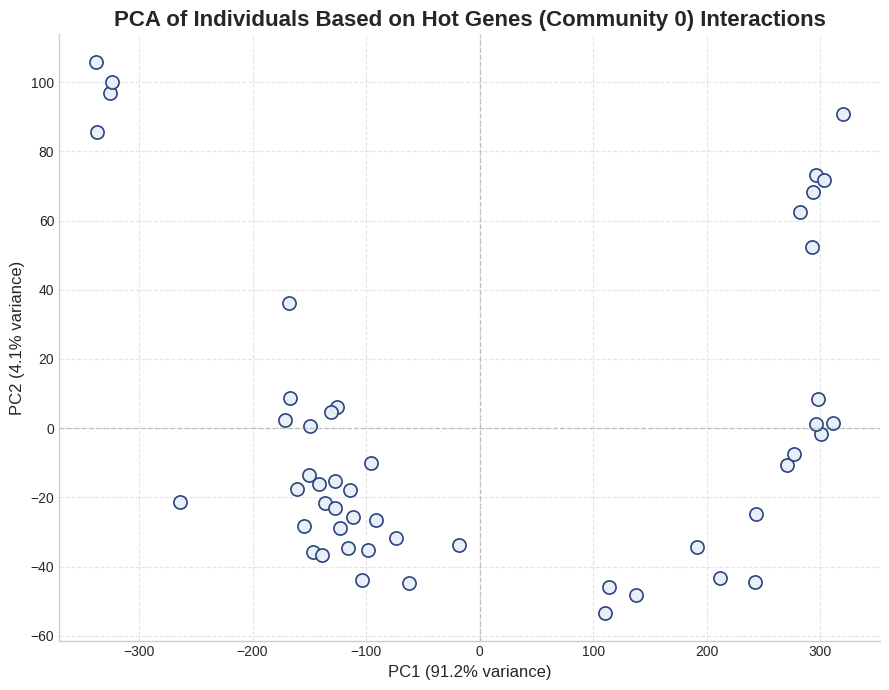

In [ ]:
# --- Imports ---
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# --- Prepara i dati (usa filtered_df già in memoria) ---
# Tieni solo le colonne numeriche (escludi meta-info)
# Extract only the numerical values (Sample_1...Sample_50)
# Extract only the numerical values (Sample_1...Sample_50)
data_values = filtered_df_0.drop(columns=["tf", "gene"])

# Transpose the data so that individuals are rows
data_indiv = data_values.T
data_indiv.index.name = "Individual"

# Perform PCA (reducing to 2 components for visualization)
pca = PCA(n_components=2)
pca_result = pca.fit_transform(data_indiv)

# Percentuali di varianza per le etichette assi
pc1_var = pca.explained_variance_ratio_[0] * 100
pc2_var = pca.explained_variance_ratio_[1] * 100

# --- Plot elegante, centro chiaro + bordo scuro ---
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    pca_result[:, 0], pca_result[:, 1],
    s=90,
    facecolors="#e8eff9",   # centro chiaro
    edgecolors="#1f3b73",   # bordo blu scuro
    linewidths=1.2,
    alpha=0.95
)

# Croci di riferimento sugli assi
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.4)
ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.4)

# Titolo e assi
ax.set_title("PCA of Individuals Based on Hot Genes (Community 0) Interactions",
             fontsize=16, weight="bold")
ax.set_xlabel(f"PC1 ({pc1_var:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({pc2_var:.1f}% variance)", fontsize=12)

# Griglia discreta + pulizia spines
ax.grid(True, linestyle="--", alpha=0.5)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


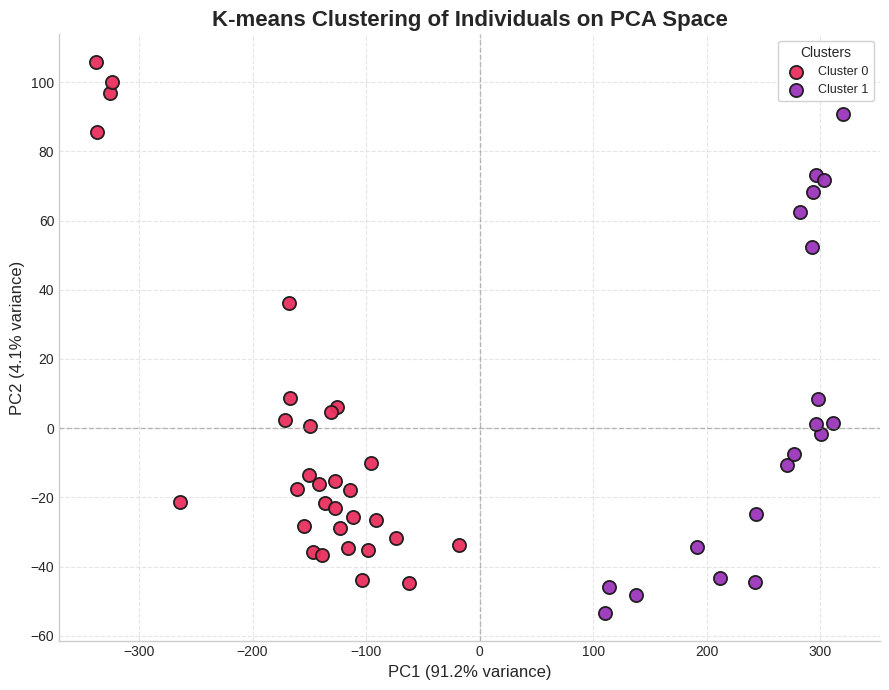

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
import numpy as np

# --- KMeans ---
n_clusters = 2
kmeans_0 = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
cluster_labels_0 = kmeans_0.fit_predict(pca_result)

# --- Palette (i tuoi colori di base) ---
base_palette = [
    "#e6194b",  # rosso vivo
    "#911eb4",  # viola vivace
]

# Funzione per schiarire i colori (blend verso bianco)
def lighten(hex_color, factor=0.85):
    rgb = np.array(mcolors.to_rgb(hex_color))
    return mcolors.to_hex(1 - factor * (1 - rgb))

face_colors = [lighten(c, 0.9) for c in base_palette[:n_clusters]]
edge_colors = ["#1a1a1a"] * n_clusters   # contorno scuro uniforme

# --- Stile coerente col PCA precedente ---
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))

# Scatter per cluster: centro chiaro, bordo scuro
for k in range(n_clusters):
    mask = (cluster_labels_0 == k)
    ax.scatter(
        pca_result[mask, 0], pca_result[mask, 1],
        s=90,
        facecolors=face_colors[k],
        edgecolors=edge_colors[k],
        linewidths=1.3,
        alpha=0.95,
        label=f"Cluster {k}"
    )

# Griglia e assi
ax.grid(True, linestyle="--", alpha=0.5)
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.5)

# Titolo e assi
ax.set_title("K-means Clustering of Individuals on PCA Space", fontsize=16, weight="bold")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)", fontsize=12)

# Legenda
leg = ax.legend(frameon=True, title="Clusters", fontsize=9)
leg.get_frame().set_alpha(0.9)

# Pulizia spines
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


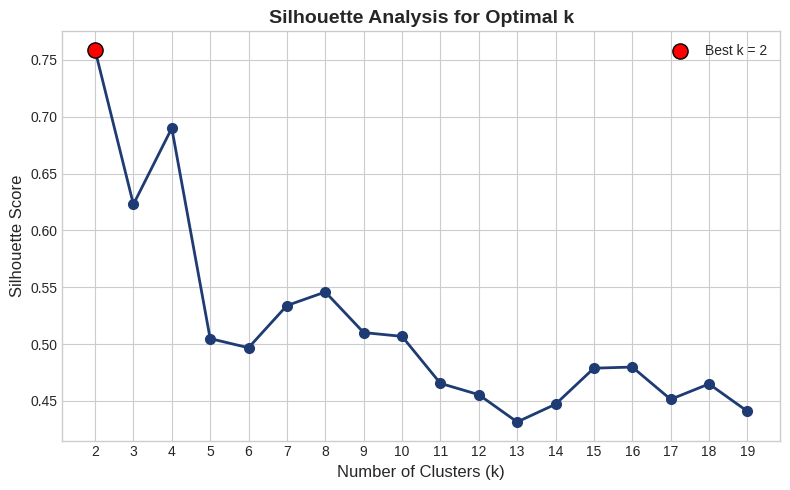

In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

silhouette_scores = []
K_range = range(2, 20)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(pca_result)
    score = silhouette_score(pca_result, labels)
    silhouette_scores.append(score)

# Trova il massimo
best_k = K_range[silhouette_scores.index(max(silhouette_scores))]
best_score = max(silhouette_scores)

# Stile elegante
plt.style.use("seaborn-v0_8-whitegrid")

# Plot linea
plt.figure(figsize=(8, 5))
plt.plot(
    K_range,
    silhouette_scores,
    marker="o",
    markersize=7,
    linewidth=2,
    color="#1f3b73",   # blu scuro
)

# Evidenzia il punto migliore
plt.scatter(
    best_k,
    best_score,
    color="red",
    s=120,              # dimensione marker
    edgecolor="black",
    zorder=5,
    label=f"Best k = {best_k}"
)

# Impostazioni asse x: solo numeri interi
plt.xticks(K_range)

# Label e titolo
plt.xlabel("Number of Clusters (k)", fontsize=12)
plt.ylabel("Silhouette Score", fontsize=12)
plt.title("Silhouette Analysis for Optimal k", fontsize=14, weight="bold")

# Legenda
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import silhouette_score

score = silhouette_score(pca_result, cluster_labels_0)
print(f"Silhouette Score: {score:.2f}")


Silhouette Score: 0.76


In [ ]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

print("Calinski-Harabasz:", calinski_harabasz_score(pca_result, cluster_labels_0))
print("Davies-Bouldin:", davies_bouldin_score(pca_result, cluster_labels_0))  # più basso è meglio


Calinski-Harabasz: 249.84243062082234
Davies-Bouldin: 0.34037943717034963


* Community 1

In [ ]:
threshold_to_extract = 'Q98.0'
cluster_to_extract = 1


genes_98_1 = [
    gene for gene, cluster_id in gene_cluster_map[threshold_to_extract].items()
    if cluster_id == cluster_to_extract
]

print(f"Genes at the threshold {threshold_to_extract}, cluster {cluster_to_extract}:")
print(genes_98_1)

len(genes_98_1)

Genes at the threshold Q98.0, cluster 1:
['APOOL', 'MAMLD1', 'TAF9B', 'CSTF2', 'PFKFB1', 'SLC6A8', 'GABRQ', 'PCDH19', 'MBTPS2', 'MAGIX', 'CDK16', 'HS6ST2', 'DDX3X', 'UPRT', 'RAP2C', 'NUDT10', 'FAM9B', 'GAGE12B', 'ZRSR2', 'CNKSR2', 'GAGE12H', 'ZNF449', 'AP1S2', 'ZNF81', 'AMOT', 'SLC25A43', 'BCORL1', 'SCML1', 'SLC25A5', 'CXorf38', 'TSPY1', 'CLCN5', 'NHS', 'NAP1L3', 'PDZD11', 'ZXDA', 'NLGN4Y', 'CITED1', 'UBQLN2', 'ARMCX2', 'RPL10', 'TBL1X', 'RIBC1', 'CHIC1', 'MORF4L2', 'VBP1', 'MBNL3', 'MAGEC3', 'BCOR', 'HMGB3']


50

In [ ]:
df = pd.read_csv("labeled_lioness_data.csv")

In [ ]:
filtered_df_1 = df[df['tf'].isin(genes_98_1) & df['gene'].isin(genes_98_1)]
filtered_df_1

,tf,gene,Sample_1,Sample_2,Sample_3,Sample_4,Sample_5,Sample_6,Sample_7,Sample_8,...,Sample_41,Sample_42,Sample_43,Sample_44,Sample_45,Sample_46,Sample_47,Sample_48,Sample_49,Sample_50
3595,AMOT,NLGN4Y,-4.434820,-6.845172,-4.933307,-3.944412,-3.903722,-3.636225,-6.620730,-3.597956,...,-3.523093,-4.504301,-2.735674,-4.148161,-4.516116,-4.222872,-5.755274,-2.961537,-4.192969,-4.103505
3596,AP1S2,NLGN4Y,-4.609661,-6.335564,-4.370484,-4.337945,-4.578776,-3.760155,-5.598587,-3.714418,...,-3.706313,-4.295037,-2.552887,-5.115966,-4.353088,-4.773629,-6.106867,-3.092386,-5.255252,-4.823384
3599,APOOL,NLGN4Y,0.375805,-14.102910,1.791068,1.760474,1.181683,-1.973829,-3.056077,-2.904581,...,0.926029,0.773093,-7.529668,-4.244820,3.928414,4.476684,16.274324,-12.865484,-0.458975,1.952912
3606,ARMCX2,NLGN4Y,3.935676,6.488421,4.051598,4.015272,4.220786,3.326118,5.300382,3.209521,...,3.151422,3.922331,2.466856,4.157897,3.946354,3.958776,3.920784,2.752773,3.875823,3.904073
3617,BCOR,NLGN4Y,3.976287,6.481866,4.016202,3.948743,3.951642,3.312253,5.937728,3.215731,...,3.215544,3.953869,2.461769,4.100202,3.950242,3.777438,4.522496,2.763876,3.991173,3.919627
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127415,VBP1,MBNL3,4.120957,5.351599,4.360725,4.087234,4.078129,3.889416,5.359765,4.151975,...,3.747854,4.009267,3.902967,3.745384,4.113864,4.318958,2.538510,4.394387,4.179307,4.162254
127437,ZNF449,MBNL3,-4.345295,-4.976721,-4.988080,-4.313793,-4.099789,-4.754633,-6.267872,-4.193145,...,-2.630585,-4.762428,-5.348794,-4.657143,-4.562540,-4.607889,-2.372738,-5.160660,-3.854398,-4.817854
127441,ZNF81,MBNL3,-4.968699,-6.049466,-5.020058,-4.833293,-4.995535,-4.558188,-5.833316,-4.343056,...,-3.197245,-4.455833,-4.420600,-5.307311,-4.465334,-4.356490,-2.698826,-4.917975,-4.798562,-4.389870
127442,ZRSR2,MBNL3,-4.964417,-6.310915,-5.367527,-4.590836,-4.267015,-3.770551,-6.263324,-4.647762,...,-3.441589,-4.747347,-4.085808,-4.341780,-4.895970,-4.490308,-2.561364,-4.202699,-4.447100,-4.247369


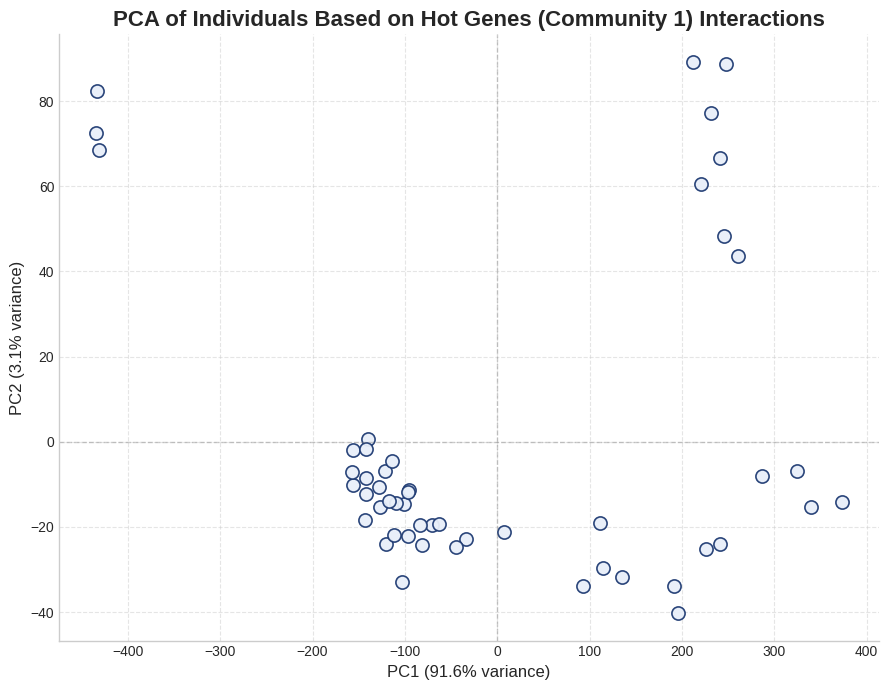

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Extract only the numerical values (Sample_1...Sample_50)
data_values = filtered_df_1.drop(columns=["tf", "gene"])

# Transpose the data so that individuals are rows
data_indiv = data_values.T
data_indiv.index.name = "Individual"

# Perform PCA (reducing to 2 components for visualization)
pca = PCA(n_components=2)
pca_result = pca.fit_transform(data_indiv)

# Percentuali di varianza per le etichette assi
pc1_var = pca.explained_variance_ratio_[0] * 100
pc2_var = pca.explained_variance_ratio_[1] * 100

# --- Plot elegante, centro chiaro + bordo scuro ---
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    pca_result[:, 0], pca_result[:, 1],
    s=90,
    facecolors="#e8eff9",   # centro chiaro
    edgecolors="#1f3b73",   # bordo blu scuro
    linewidths=1.2,
    alpha=0.95
)

# Croci di riferimento sugli assi
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.4)
ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.4)

# Titolo e assi
ax.set_title("PCA of Individuals Based on Hot Genes (Community 1) Interactions",
             fontsize=16, weight="bold")
ax.set_xlabel(f"PC1 ({pc1_var:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({pc2_var:.1f}% variance)", fontsize=12)

# Griglia discreta + pulizia spines
ax.grid(True, linestyle="--", alpha=0.5)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()



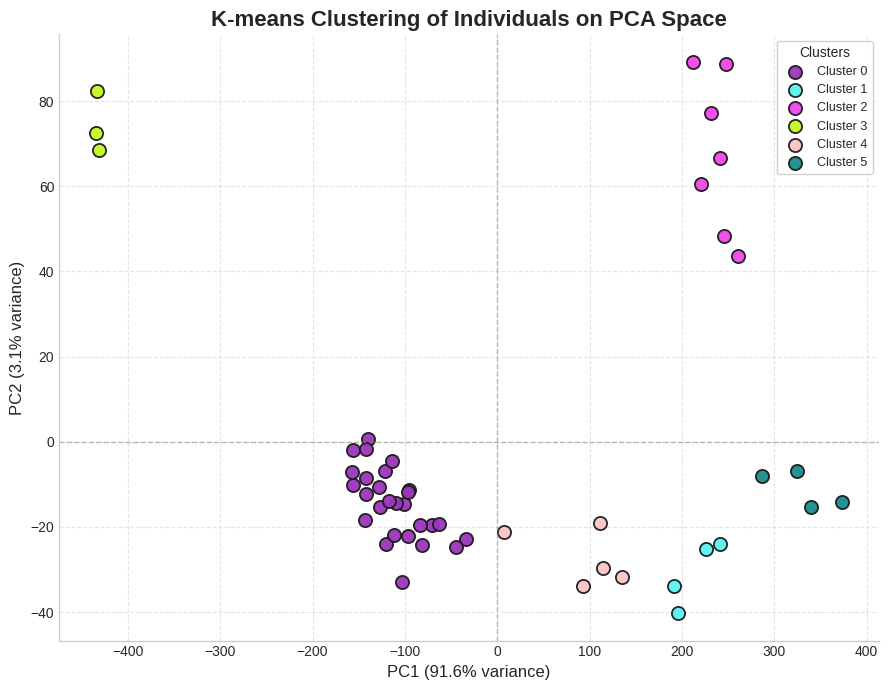

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
import numpy as np

# --- KMeans ---
n_clusters = 6
kmeans_1 = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
cluster_labels_1 = kmeans_1.fit_predict(pca_result)

# --- Palette (i tuoi colori di base) ---
base_palette = [
    "#911eb4",  # viola vivace
    "#46f0f0",  # ciano brillante
    "#f032e6",  # rosa acceso
    "#bcf60c",  # lime elettrico
    "#fabebe",  # rosa chiaro
    "#008080"   # teal profondo
]

# Funzione per schiarire i colori (blend verso bianco)
def lighten(hex_color, factor=0.85):
    rgb = np.array(mcolors.to_rgb(hex_color))
    return mcolors.to_hex(1 - factor * (1 - rgb))

face_colors = [lighten(c, 0.9) for c in base_palette[:n_clusters]]
edge_colors = ["#1a1a1a"] * n_clusters   # contorno scuro uniforme

# --- Stile coerente col PCA precedente ---
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))

# Scatter per cluster: centro chiaro, bordo scuro
for k in range(n_clusters):
    mask = (cluster_labels_1 == k)
    ax.scatter(
        pca_result[mask, 0], pca_result[mask, 1],
        s=90,
        facecolors=face_colors[k],
        edgecolors=edge_colors[k],
        linewidths=1.3,
        alpha=0.95,
        label=f"Cluster {k}"
    )

# Griglia e assi
ax.grid(True, linestyle="--", alpha=0.5)
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.5)

# Titolo e assi
ax.set_title("K-means Clustering of Individuals on PCA Space", fontsize=16, weight="bold")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)", fontsize=12)

# Legenda
leg = ax.legend(frameon=True, title="Clusters", fontsize=9)
leg.get_frame().set_alpha(0.9)

# Pulizia spines
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


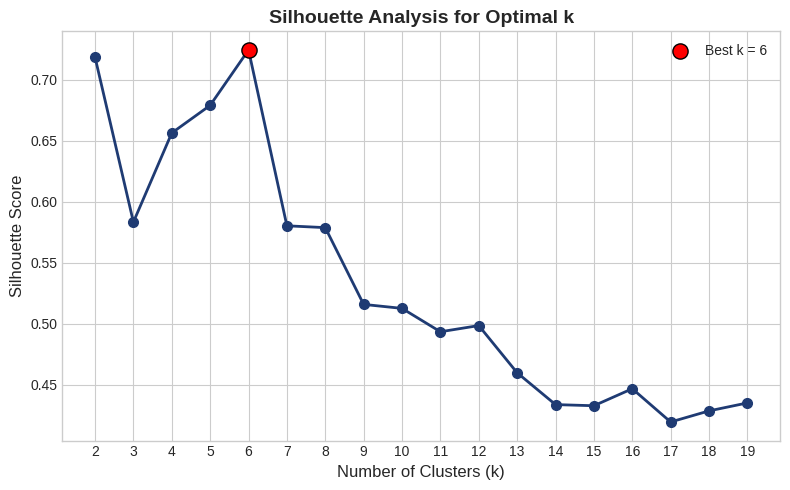

In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

silhouette_scores = []
K_range = range(2, 20)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(pca_result)
    score = silhouette_score(pca_result, labels)
    silhouette_scores.append(score)

# Trova il massimo
best_k = K_range[silhouette_scores.index(max(silhouette_scores))]
best_score = max(silhouette_scores)

# Stile elegante
plt.style.use("seaborn-v0_8-whitegrid")

# Plot linea
plt.figure(figsize=(8, 5))
plt.plot(
    K_range,
    silhouette_scores,
    marker="o",
    markersize=7,
    linewidth=2,
    color="#1f3b73",   # blu scuro
)

# Evidenzia il punto migliore
plt.scatter(
    best_k,
    best_score,
    color="red",
    s=120,              # dimensione marker
    edgecolor="black",
    zorder=5,
    label=f"Best k = {best_k}"
)

# Impostazioni asse x: solo numeri interi
plt.xticks(K_range)

# Label e titolo
plt.xlabel("Number of Clusters (k)", fontsize=12)
plt.ylabel("Silhouette Score", fontsize=12)
plt.title("Silhouette Analysis for Optimal k", fontsize=14, weight="bold")

# Legenda
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import silhouette_score

score = silhouette_score(pca_result, cluster_labels_1)
print(f"Silhouette Score: {score:.2f}")


Silhouette Score: 0.72


In [ ]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

print("Calinski-Harabasz:", calinski_harabasz_score(pca_result, cluster_labels_1))
print("Davies-Bouldin:", davies_bouldin_score(pca_result, cluster_labels_1))  # più basso è meglio


Calinski-Harabasz: 354.73067762864457
Davies-Bouldin: 0.3589871750169449


* Community 2

In [ ]:
threshold_to_extract = 'Q98.0'
cluster_to_extract = 2


genes_98_2 = [
    gene for gene, cluster_id in gene_cluster_map[threshold_to_extract].items()
    if cluster_id == cluster_to_extract
]

print(f"Genes at the threshold {threshold_to_extract}, cluster {cluster_to_extract}:")
print(genes_98_2)

len(genes_98_2)

Genes at the threshold Q98.0, cluster 2:
['LONRF3', 'AFF2', 'FGF16', 'NDP', 'RPS4X', 'PIM2', 'DUSP9', 'OTUD5', 'BEND2', 'HCFC1', 'FAM47C', 'IL1RAPL1', 'TMEM187', 'PJA1', 'FAM3A', 'DYNLT3', 'STARD8', 'SH3BGRL', 'PRRG3', 'PGK1', 'UBL4A', 'ARMCX1', 'DDX3Y', 'NAA10', 'SHROOM2', 'RPGR', 'FGF13']


27

In [ ]:
df = pd.read_csv("labeled_lioness_data.csv")

In [ ]:
filtered_df_2 = df[df['tf'].isin(genes_98_2) & df['gene'].isin(genes_98_2)]
filtered_df_2

,tf,gene,Sample_1,Sample_2,Sample_3,Sample_4,Sample_5,Sample_6,Sample_7,Sample_8,...,Sample_41,Sample_42,Sample_43,Sample_44,Sample_45,Sample_46,Sample_47,Sample_48,Sample_49,Sample_50
4309,AFF2,DDX3Y,-3.497957,0.301565,-6.035389,0.838791,-2.972838,-0.151382,4.026279,-6.390880,...,-3.458655,-7.970091,-5.066368,-1.834662,-10.158025,0.431540,11.003194,-14.613444,12.501355,-0.783704
4323,ARMCX1,DDX3Y,4.741937,7.232665,6.828576,5.450266,5.270240,5.724410,7.451952,5.273979,...,4.533372,5.775866,6.474774,4.582278,5.975680,4.995212,6.546160,6.547773,5.855557,4.896327
4337,BEND2,DDX3Y,5.270205,7.134901,5.605310,6.270279,6.567918,4.748373,7.384638,6.028813,...,3.609655,5.321927,4.407858,4.679039,5.482093,4.641431,7.359364,5.554317,6.425682,4.405850
4369,DDX3Y,DDX3Y,5.194754,6.678103,6.320446,6.321029,6.240734,5.745509,7.061399,5.722846,...,4.644026,5.969077,6.915045,5.174004,6.503219,4.963753,6.297448,6.687734,5.479178,4.847242
4375,DUSP9,DDX3Y,5.052176,7.620020,5.501560,6.402841,6.601702,5.609734,7.082215,6.608869,...,3.632546,5.078923,5.853986,3.915407,5.367270,4.553061,6.606850,6.276072,6.286277,4.217149
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
126990,SH3BGRL,FAM47C,5.920459,7.142917,6.291602,5.623383,5.249932,5.615353,7.601277,4.797143,...,5.382800,6.091825,6.150648,4.563164,6.308244,4.316938,6.404601,6.055075,5.531936,5.412381
126992,SHROOM2,FAM47C,5.668608,7.110494,6.071915,4.909860,5.406495,5.271699,6.986549,3.889065,...,6.032179,5.859087,6.374446,5.492036,5.908430,4.826635,6.158062,6.822101,4.777745,4.937105
127010,STARD8,FAM47C,6.276469,7.464212,6.804435,5.583409,5.287929,5.469845,7.542888,4.123251,...,6.221674,6.549233,7.039585,4.566117,7.180638,4.711596,6.461648,6.950386,4.722285,5.274657
127031,TMEM187,FAM47C,4.826091,7.117797,5.742372,5.385257,6.365418,5.370285,6.446582,4.284435,...,5.436779,5.430231,5.691813,5.231144,5.708966,4.220586,6.393104,6.223638,5.144138,6.034710


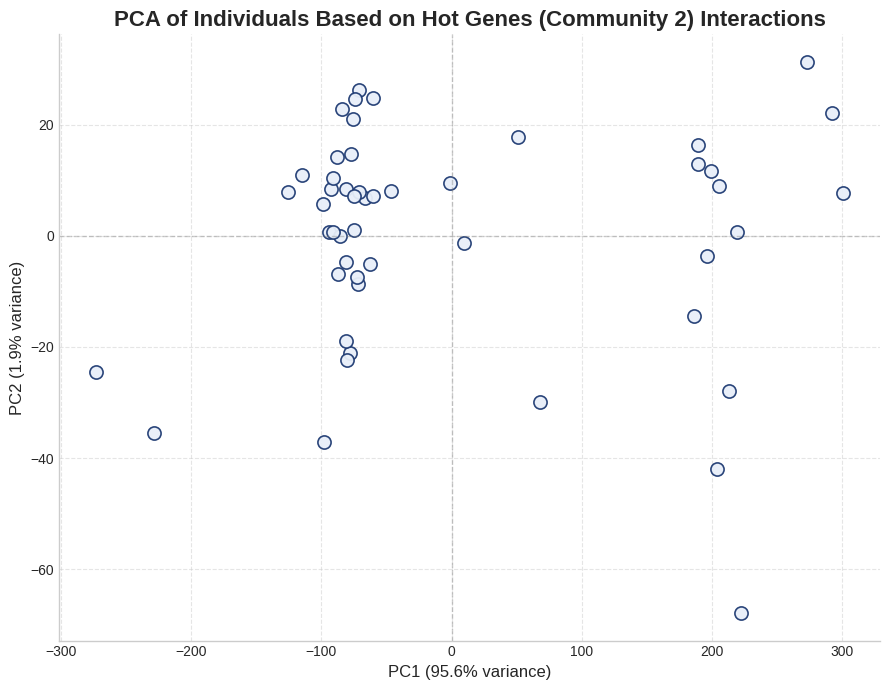

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Extract only the numerical values (Sample_1...Sample_50)
data_values = filtered_df_2.drop(columns=["tf", "gene"])

# Transpose the data so that individuals are rows
data_indiv = data_values.T
data_indiv.index.name = "Individual"

# Perform PCA (reducing to 2 components for visualization)
pca = PCA(n_components=2)
pca_result = pca.fit_transform(data_indiv)

# Percentuali di varianza per le etichette assi
pc1_var = pca.explained_variance_ratio_[0] * 100
pc2_var = pca.explained_variance_ratio_[1] * 100

# --- Plot elegante, centro chiaro + bordo scuro ---
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    pca_result[:, 0], pca_result[:, 1],
    s=90,
    facecolors="#e8eff9",   # centro chiaro
    edgecolors="#1f3b73",   # bordo blu scuro
    linewidths=1.2,
    alpha=0.95
)

# Croci di riferimento sugli assi
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.4)
ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.4)

# Titolo e assi
ax.set_title("PCA of Individuals Based on Hot Genes (Community 2) Interactions",
             fontsize=16, weight="bold")
ax.set_xlabel(f"PC1 ({pc1_var:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({pc2_var:.1f}% variance)", fontsize=12)

# Griglia discreta + pulizia spines
ax.grid(True, linestyle="--", alpha=0.5)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()



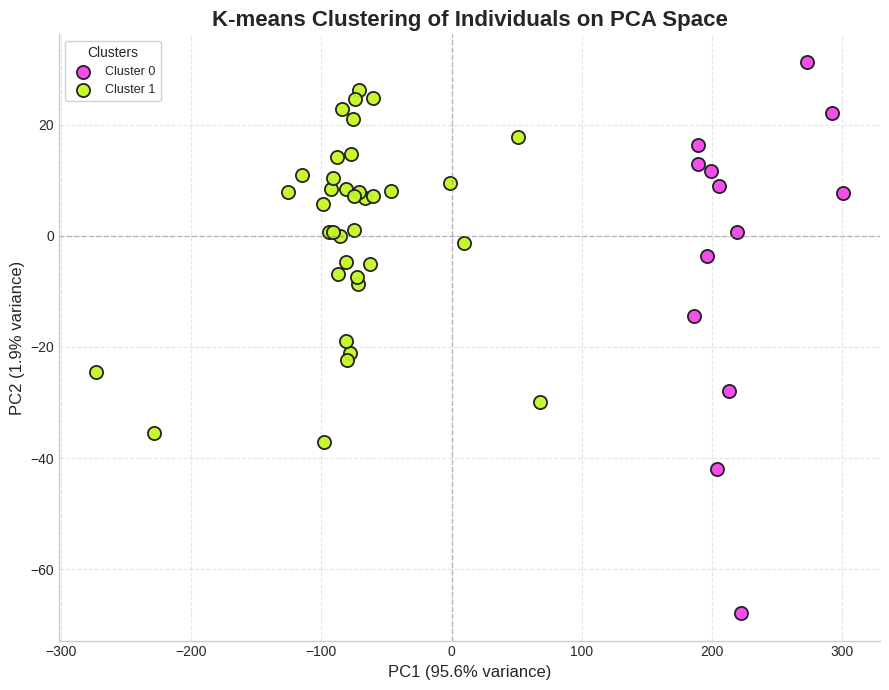

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
import numpy as np

# --- KMeans ---
n_clusters = 2
kmeans_2 = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
cluster_labels_2 = kmeans_2.fit_predict(pca_result)

# --- Palette (i tuoi colori di base) ---
base_palette = [
    "#f032e6",  # rosa acceso
    "#bcf60c",  # lime elettrico
]

# Funzione per schiarire i colori (blend verso bianco)
def lighten(hex_color, factor=0.85):
    rgb = np.array(mcolors.to_rgb(hex_color))
    return mcolors.to_hex(1 - factor * (1 - rgb))

face_colors = [lighten(c, 0.9) for c in base_palette[:n_clusters]]
edge_colors = ["#1a1a1a"] * n_clusters   # contorno scuro uniforme

# --- Stile coerente col PCA precedente ---
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))

# Scatter per cluster: centro chiaro, bordo scuro
for k in range(n_clusters):
    mask = (cluster_labels_2 == k)
    ax.scatter(
        pca_result[mask, 0], pca_result[mask, 1],
        s=90,
        facecolors=face_colors[k],
        edgecolors=edge_colors[k],
        linewidths=1.3,
        alpha=0.95,
        label=f"Cluster {k}"
    )

# Griglia e assi
ax.grid(True, linestyle="--", alpha=0.5)
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.5)

# Titolo e assi
ax.set_title("K-means Clustering of Individuals on PCA Space", fontsize=16, weight="bold")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)", fontsize=12)

# Legenda
leg = ax.legend(frameon=True, title="Clusters", fontsize=9)
leg.get_frame().set_alpha(0.9)

# Pulizia spines
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


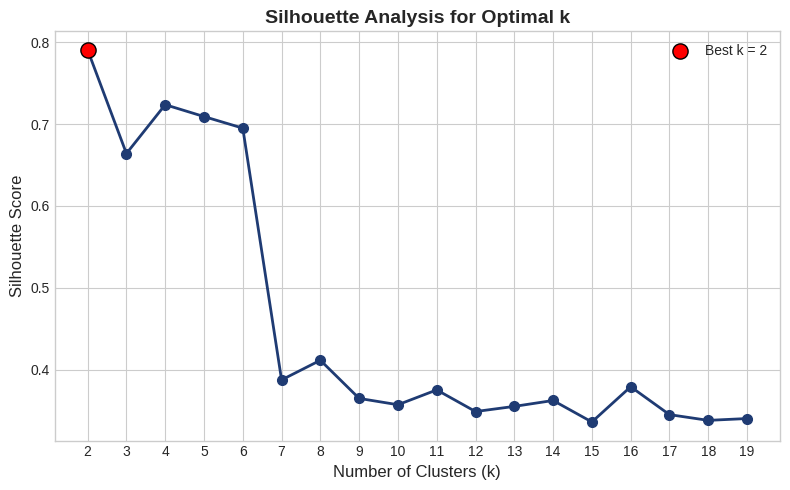

In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

silhouette_scores = []
K_range = range(2, 20)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(pca_result)
    score = silhouette_score(pca_result, labels)
    silhouette_scores.append(score)

# Trova il massimo
best_k = K_range[silhouette_scores.index(max(silhouette_scores))]
best_score = max(silhouette_scores)

# Stile elegante
plt.style.use("seaborn-v0_8-whitegrid")

# Plot linea
plt.figure(figsize=(8, 5))
plt.plot(
    K_range,
    silhouette_scores,
    marker="o",
    markersize=7,
    linewidth=2,
    color="#1f3b73",   # blu scuro
)

# Evidenzia il punto migliore
plt.scatter(
    best_k,
    best_score,
    color="red",
    s=120,              # dimensione marker
    edgecolor="black",
    zorder=5,
    label=f"Best k = {best_k}"
)

# Impostazioni asse x: solo numeri interi
plt.xticks(K_range)

# Label e titolo
plt.xlabel("Number of Clusters (k)", fontsize=12)
plt.ylabel("Silhouette Score", fontsize=12)
plt.title("Silhouette Analysis for Optimal k", fontsize=14, weight="bold")

# Legenda
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import silhouette_score

score = silhouette_score(pca_result, cluster_labels_2)
print(f"Silhouette Score: {score:.2f}")


Silhouette Score: 0.79


In [ ]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

print("Calinski-Harabasz:", calinski_harabasz_score(pca_result, cluster_labels_2))
print("Davies-Bouldin:", davies_bouldin_score(pca_result, cluster_labels_2))  # più basso è meglio


Calinski-Harabasz: 263.02913447390875
Davies-Bouldin: 0.2630870148168854


# **3) Sankey to compare PCA+Kmeans results**

In [ ]:
import pandas as pd
import plotly.graph_objects as go

# Lista di colori brillanti e distinti (fino a 21)
distinct_colors = [
    "rgb(230, 25, 75)", "rgb(60, 180, 75)", "rgb(255, 225, 25)", "rgb(0, 130, 200)", "rgb(245, 130, 48)",
    "rgb(145, 30, 180)", "rgb(70, 240, 240)", "rgb(240, 50, 230)", "rgb(210, 245, 60)", "rgb(250, 190, 190)",
    "rgb(0, 128, 128)", "rgb(230, 190, 255)", "rgb(170, 110, 40)", "rgb(255, 250, 200)", "rgb(128, 0, 0)",
    "rgb(170, 255, 195)", "rgb(0, 0, 128)", "rgb(128, 128, 0)", "rgb(255, 215, 180)", "rgb(128, 64, 0)",
    "rgb(255, 100, 255)"
]

# Create DataFrame from cluster label arrays
df_clusters = pd.DataFrame({
    'All Genes': cluster_labels_all,
    'Hot Genes': cluster_labels_hot,
    'Community 0': cluster_labels_0,
    'Community 1': cluster_labels_1,
    'Community 2': cluster_labels_2
})

# Build labels
label_list = []
label_color = {}
color_index = 0
for col in df_clusters.columns:
    clusters = df_clusters[col].unique()
    for c in clusters:
        label = f"{col}: Cluster {c}"
        label_list.append(label)
        label_color[label] = distinct_colors[color_index % len(distinct_colors)]
        color_index += 1
label_list = list(dict.fromkeys(label_list))  # Remove duplicates

# Map labels to indices
label_to_index = {label: i for i, label in enumerate(label_list)}

# Build source, target, value, link colors
source = []
target = []
value = []
link_colors = []

for i in range(len(df_clusters.columns) - 1):
    col1 = df_clusters.columns[i]
    col2 = df_clusters.columns[i + 1]
    grouped = df_clusters.groupby([col1, col2]).size().reset_index(name='count')
    for _, row in grouped.iterrows():
        src_label = f"{col1}: Cluster {row[col1]}"
        tgt_label = f"{col2}: Cluster {row[col2]}"
        source.append(label_to_index[src_label])
        target.append(label_to_index[tgt_label])
        value.append(row['count'])

        # Create rgba color with transparency from the source node color
        base_rgb = label_color[src_label]
        rgba_color = base_rgb.replace("rgb", "rgba").replace(")", ", 0.4)")
        link_colors.append(rgba_color)

# Sankey diagram
fig = go.Figure(data=[go.Sankey(
    arrangement='snap',
    node=dict(
        pad=15,
        thickness=25,
        line=dict(color="gray", width=0.5),
        label=label_list,
        color=[label_color[label] for label in label_list],
        hovertemplate='Cluster: %{label}<extra></extra>'
    ),
    link=dict(
        source=source,
        target=target,
        value=value,
        color=link_colors,
        hovertemplate='From %{source.label} to %{target.label}<br>Count: %{value}<extra></extra>'
    )
)])

fig.update_layout(
    title_text="Sankey Diagram: Comparison of Clustering Assignments Across Gene Groups",
    font=dict(size=12, color='black'),
    height=700,
    width=1100,
    margin=dict(l=10, r=10, t=40, b=10),
    paper_bgcolor='white',
    plot_bgcolor='white',
    title_x=0.5
)

fig.show()


# **5) Heatmaps to Compare**

In [ ]:
import pandas as pd
import numpy as np

# Colonne con i dati dei sample
sample_cols = [col for col in filtered_df.columns if col.startswith('Sample_')]
X_hot = filtered_df[sample_cols].values

# Trasponi: individui come righe
X_hot_T = X_hot.T


In [ ]:
import pandas as pd
import numpy as np

# Colonne con i dati dei sample
sample_cols = [col for col in df.columns if col.startswith('Sample_')]
X_all = df[sample_cols].values

# Trasponi: individui come righe
X_all_T = X_all.T


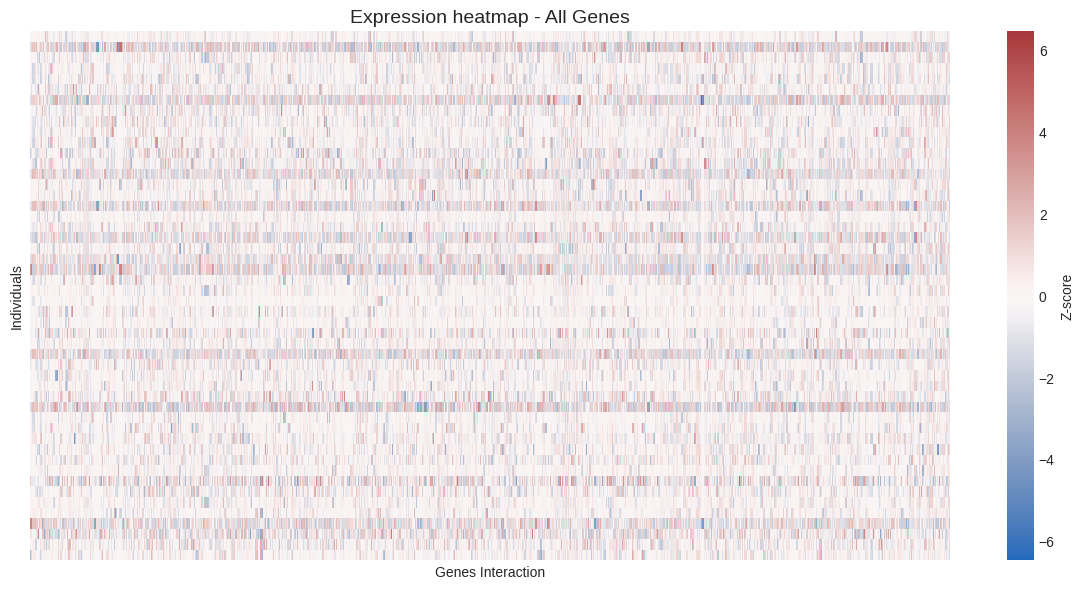

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Normalizza
scaler = StandardScaler()
hot_scaled = scaler.fit_transform(X_all_T)

# Plot
plt.figure(figsize=(12, 6))
ax = sns.heatmap(hot_scaled, cmap='vlag', cbar_kws={'label': 'Z-score'})

# Rimuovi tick labels
ax.set_xticks([])
ax.set_yticks([])

# Aggiungi solo nomi degli assi
ax.set_xlabel('Genes Interaction')
ax.set_ylabel('Individuals')
ax.set_title('Expression heatmap - All Genes', fontsize=14)

plt.tight_layout()
plt.show()


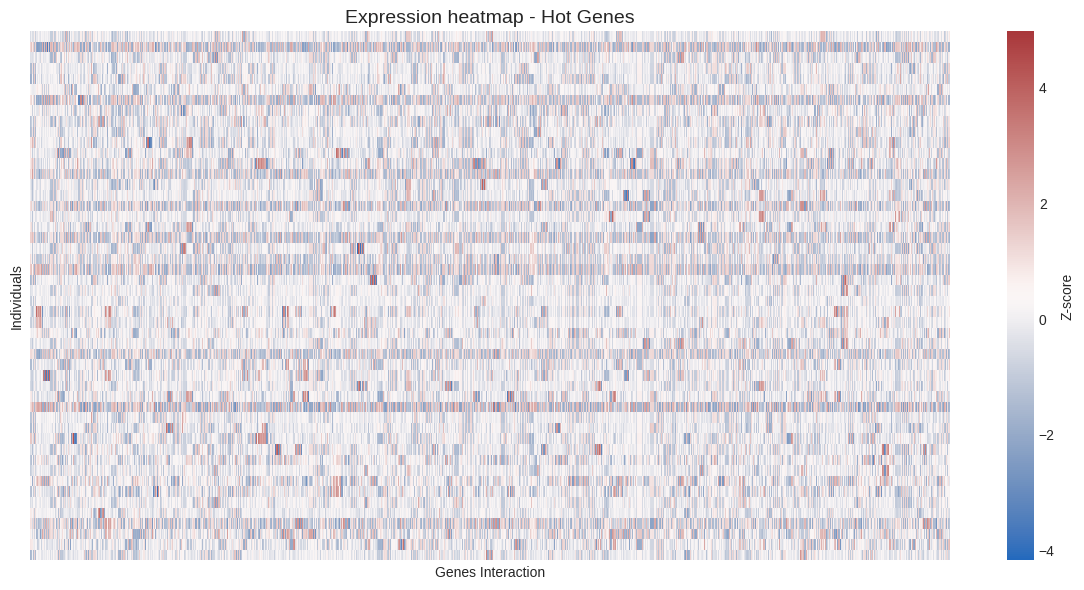

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Normalizza
scaler = StandardScaler()
hot_scaled = scaler.fit_transform(X_hot_T)

# Plot
plt.figure(figsize=(12, 6))
ax = sns.heatmap(hot_scaled, cmap='vlag', cbar_kws={'label': 'Z-score'})

# Rimuovi tick labels
ax.set_xticks([])
ax.set_yticks([])

# Aggiungi solo nomi degli assi
ax.set_xlabel('Genes Interaction')
ax.set_ylabel('Individuals')
ax.set_title('Expression heatmap - Hot Genes', fontsize=14)

plt.tight_layout()
plt.show()


# **6) T-sne**

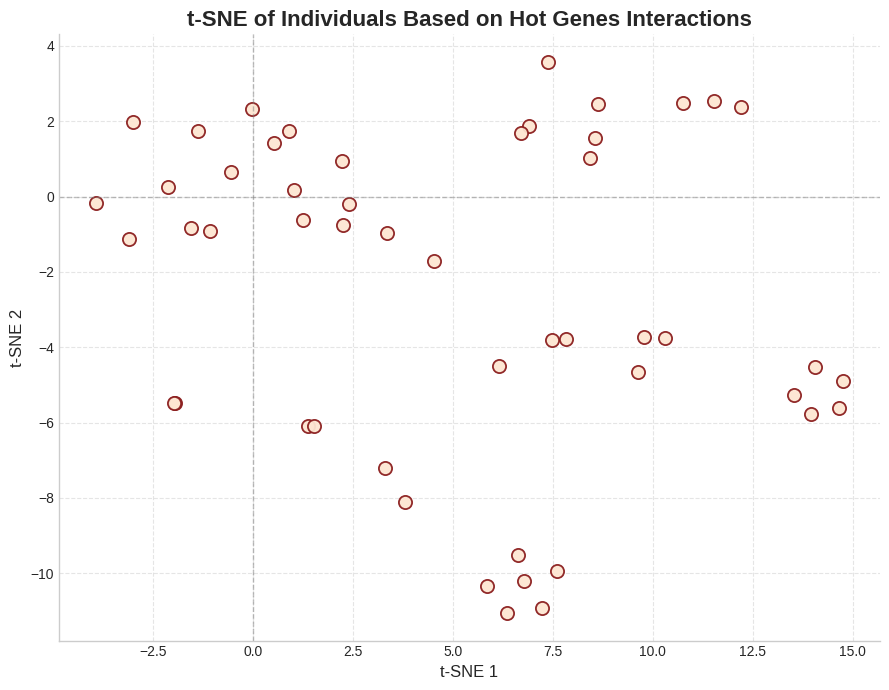

In [ ]:
# **6) t-SNE — Hot genes (scatter)**
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Esegui t-SNE (Hot)
tsne_hot = TSNE(n_components=2, perplexity=10, random_state=42)
tsne_results_hot = tsne_hot.fit_transform(X_hot_T)

# Stile coerente con il PCA
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))

# Marker: centro chiaro + bordo scuro
face_color = "#FDE6D2"
edge_color = "#8B1E1E"

ax.scatter(
    tsne_results_hot[:, 0], tsne_results_hot[:, 1],
    s=90, facecolors=face_color, edgecolors=edge_color,
    linewidths=1.3, alpha=0.95
)

ax.grid(True, linestyle="--", alpha=0.5)
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.5)

ax.set_title("t-SNE of Individuals Based on Hot Genes Interactions", fontsize=16, weight="bold")
ax.set_xlabel("t-SNE 1", fontsize=12)
ax.set_ylabel("t-SNE 2", fontsize=12)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


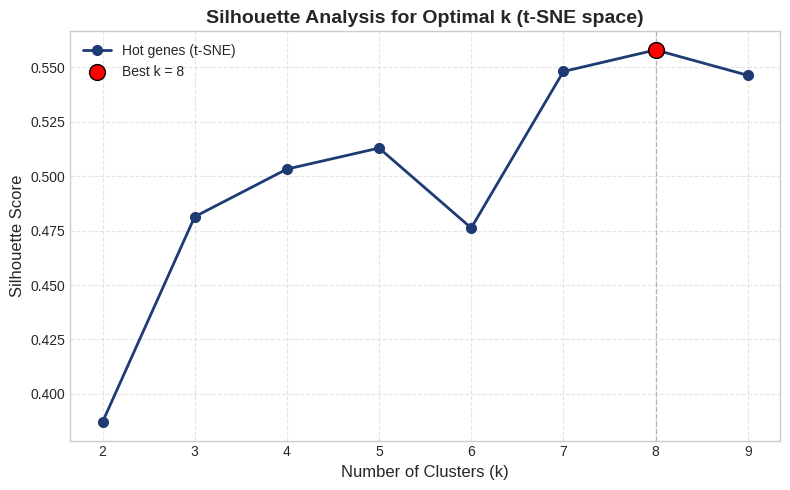

[HOT | t-SNE] Best k = 8 | Silhouette = 0.5580
Silhouette (t-SNE): 0.558 | Calinski-Harabasz: 107.6 | Davies-Bouldin: 0.518


In [ ]:
# ==== HOT GENES: tutto su t-SNE (silhouette + scelta k) ====
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import matplotlib.pyplot as plt
import numpy as np

# Riusa embedding t-SNE già calcolato
X_tsne = tsne_results_hot
n_samples = X_tsne.shape[0]

# Silhouette su t-SNE per k in [2..min(9, n-1)]
K_range = list(range(2, min(9, n_samples - 1) + 1))
scores, ks_valid = [], []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    labels = km.fit_predict(X_tsne)
    if len(np.unique(labels)) < 2:
        continue
    scores.append(silhouette_score(X_tsne, labels))
    ks_valid.append(k)

scores = np.array(scores); ks_valid = np.array(ks_valid)
best_idx = int(np.argmax(scores)); best_k = int(ks_valid[best_idx]); best_score = float(scores[best_idx])

# Plot silhouette
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ks_valid, scores, marker="o", markersize=7, linewidth=2, color="#1f3b73", label="Hot genes (t-SNE)")
ax.scatter(best_k, best_score, s=130, color="red", edgecolor="black", zorder=5, label=f"Best k = {best_k}")
ax.axvline(best_k, ls="--", lw=1, color="gray", alpha=0.5)
ax.set_xticks(ks_valid)
ax.set_xlabel("Number of Clusters (k)", fontsize=12)
ax.set_ylabel("Silhouette Score", fontsize=12)
ax.set_title("Silhouette Analysis for Optimal k (t-SNE space)", fontsize=14, weight="bold")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout(); plt.show()

print(f"[HOT | t-SNE] Best k = {best_k} | Silhouette = {best_score:.4f}")

# KMeans definitivo nel t-SNE + metriche
kmeans_hot_tsne = KMeans(n_clusters=best_k, random_state=42, n_init='auto')
cluster_labels_hot_tsne = kmeans_hot_tsne.fit_predict(X_tsne)

sil = silhouette_score(X_tsne, cluster_labels_hot_tsne)
ch  = calinski_harabasz_score(X_tsne, cluster_labels_hot_tsne)
db  = davies_bouldin_score(X_tsne, cluster_labels_hot_tsne)
print(f"Silhouette (t-SNE): {sil:.3f} | Calinski-Harabasz: {ch:.1f} | Davies-Bouldin: {db:.3f}")


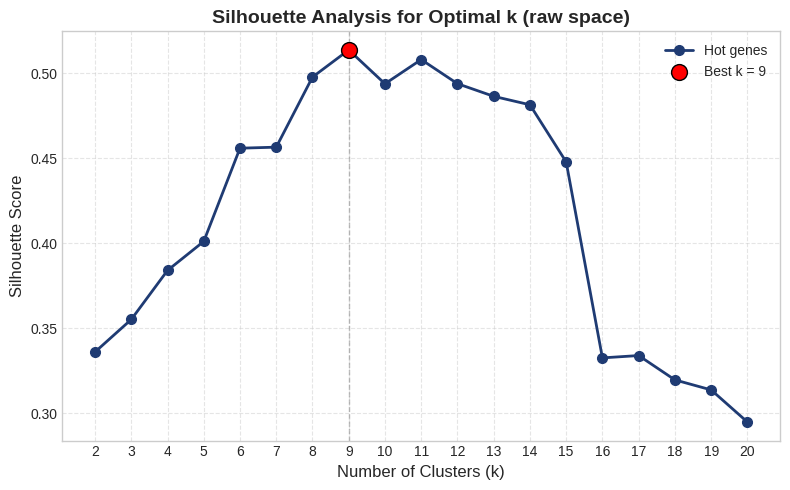

[Hot genes | raw space] Best k = 9 | Silhouette = 0.5137


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Curva silhouette senza standardizzazione/PCA (voluto)
def silhouette_curve_raw(X, max_k=20, seed=42, n_init=25):
    n = X.shape[0]  # samples
    Ks = list(range(2, min(max_k, n-1) + 1))  # evita K >= n
    scores = []
    for k in Ks:
        try:
            km = KMeans(n_clusters=k, random_state=seed, n_init=n_init)
            labels = km.fit_predict(X)
            # silhouette richiede almeno 2 cluster distinti
            if len(np.unique(labels)) < 2:
                scores.append(np.nan)
            else:
                scores.append(silhouette_score(X, labels))
        except Exception:
            scores.append(np.nan)
    return Ks, scores

# Calcola curva (X_hot_T: samples x edges)
K_axis, silhouette_hot = silhouette_curve_raw(X_hot_T, max_k=20, seed=42, n_init=25)


# --- Plot con la grafica richiesta (blu scuro + punto rosso + vline) ---
arr = np.array(silhouette_hot, dtype=float)
mask = ~np.isnan(arr)
ks_valid = np.array(K_axis)[mask]
scores_valid = arr[mask]

# trova il best k sui valori validi
best_idx = int(np.argmax(scores_valid))
best_k = int(ks_valid[best_idx])
best_s = float(scores_valid[best_idx])

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))

# linea blu scuro con marker tondi
ax.plot(ks_valid, scores_valid, marker="o", markersize=7, linewidth=2, color="#1f3b73",
        label="Hot genes")

# punto migliore rosso con bordo nero
ax.scatter(best_k, best_s, s=130, color="red", edgecolor="black", zorder=5,
           label=f"Best k = {best_k}")

# linea verticale tratteggiata sul best k
ax.axvline(best_k, ls="--", lw=1, color="gray", alpha=0.5)

ax.set_xticks(ks_valid)
ax.set_xlabel("Number of Clusters (k)", fontsize=12)
ax.set_ylabel("Silhouette Score", fontsize=12)
ax.set_title("Silhouette Analysis for Optimal k (raw space)", fontsize=14, weight="bold")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

print(f"[Hot genes | raw space] Best k = {best_k} | Silhouette = {best_s:.4f}")



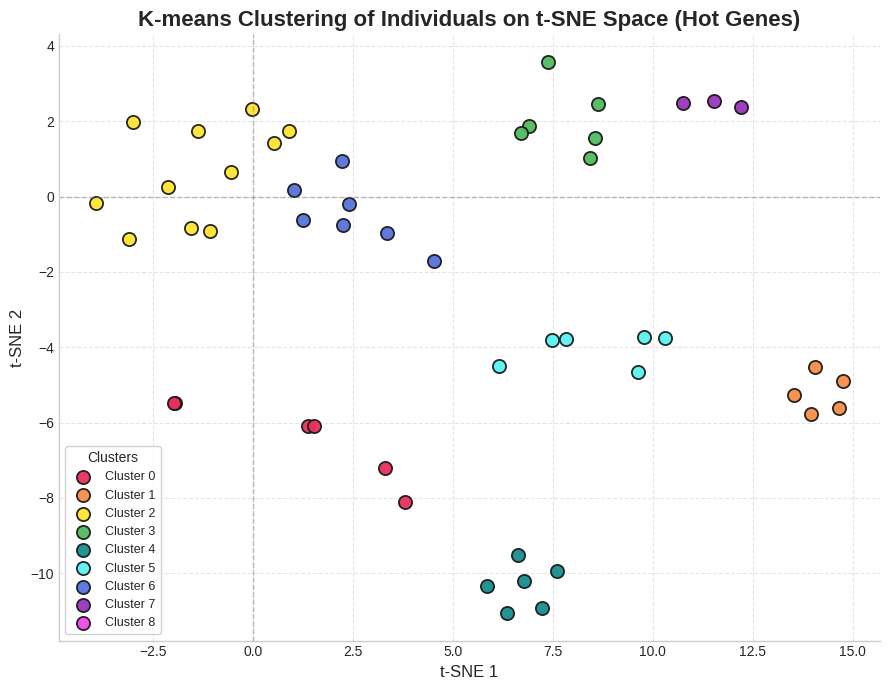

In [ ]:
# Plot cluster (Hot) su t-SNE con best_k
from matplotlib import colors as mcolors

base_palette = [
    "#e6194b", "#f58231", "#ffe119", "#3cb44b", "#008080", "#46f0f0",
    "#4363d8", "#911eb4", "#f032e6", "#a52a2a", "#7f7f7f", "#bcf60c",
]
def lighten(hex_color, factor=0.9):
    rgb = np.array(mcolors.to_rgb(hex_color))
    return mcolors.to_hex(1 - factor * (1 - rgb))

edge_color = "#1a1a1a"
face_colors = [lighten(base_palette[i % len(base_palette)], 0.9) for i in range(best_k)]

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))
for k in range(best_k):
    mask = (cluster_labels_hot_tsne == k)
    ax.scatter(
        X_tsne[mask, 0], X_tsne[mask, 1],
        s=90, facecolors=face_colors[k], edgecolors=edge_color,
        linewidths=1.3, alpha=0.95, label=f"Cluster {k}"
    )

ax.grid(True, linestyle="--", alpha=0.5)
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.set_title("K-means Clustering of Individuals on t-SNE Space (Hot Genes)", fontsize=16, weight="bold")
ax.set_xlabel("t-SNE 1", fontsize=12)
ax.set_ylabel("t-SNE 2", fontsize=12)
for spine in ["top","right"]: ax.spines[spine].set_visible(False)
leg = ax.legend(frameon=True, title="Clusters", fontsize=9); leg.get_frame().set_alpha(0.9)
plt.tight_layout(); plt.show()


ALL GENES

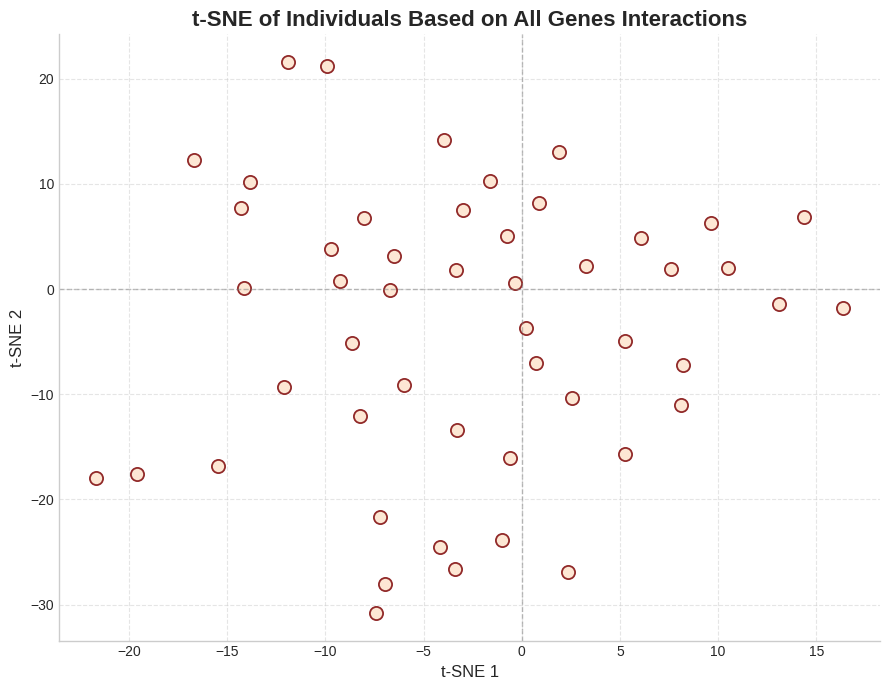

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Esegui t-SNE (All)
tsne_all = TSNE(n_components=2, perplexity=10, random_state=42)
tsne_results_all = tsne_all.fit_transform(X_all_T)

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))
face_color = "#FDE6D2"; edge_color = "#8B1E1E"

ax.scatter(tsne_results_all[:, 0], tsne_results_all[:, 1],
           s=90, facecolors=face_color, edgecolors=edge_color, linewidths=1.3, alpha=0.95)

ax.grid(True, linestyle="--", alpha=0.5)
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.5)

ax.set_title("t-SNE of Individuals Based on All Genes Interactions", fontsize=16, weight="bold")
ax.set_xlabel("t-SNE 1", fontsize=12)
ax.set_ylabel("t-SNE 2", fontsize=12)
for spine in ["top", "right"]: ax.spines[spine].set_visible(False)
plt.tight_layout(); plt.show()


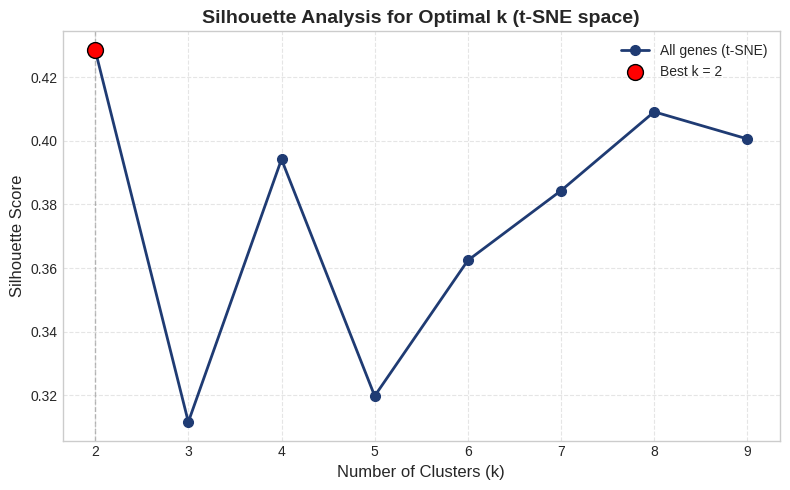

[ALL | t-SNE] Best k = 2 | Silhouette = 0.4286
Silhouette (t-SNE): 0.429 | Calinski-Harabasz: 48.9 | Davies-Bouldin: 0.864


In [ ]:
# ==== ALL GENES: tutto su t-SNE (silhouette + scelta k) ====
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import matplotlib.pyplot as plt
import numpy as np

X_tsne = tsne_results_all
n_samples = X_tsne.shape[0]

K_range = list(range(2, min(9, n_samples - 1) + 1))
scores, ks_valid = [], []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    labels = km.fit_predict(X_tsne)
    if len(np.unique(labels)) < 2:
        continue
    scores.append(silhouette_score(X_tsne, labels))
    ks_valid.append(k)

scores = np.array(scores); ks_valid = np.array(ks_valid)
best_idx = int(np.argmax(scores)); best_k = int(ks_valid[best_idx]); best_score = float(scores[best_idx])

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ks_valid, scores, marker="o", markersize=7, linewidth=2, color="#1f3b73", label="All genes (t-SNE)")
ax.scatter(best_k, best_score, s=130, color="red", edgecolor="black", zorder=5, label=f"Best k = {best_k}")
ax.axvline(best_k, ls="--", lw=1, color="gray", alpha=0.5)
ax.set_xticks(ks_valid)
ax.set_xlabel("Number of Clusters (k)", fontsize=12)
ax.set_ylabel("Silhouette Score", fontsize=12)
ax.set_title("Silhouette Analysis for Optimal k (t-SNE space)", fontsize=14, weight="bold")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout(); plt.show()

print(f"[ALL | t-SNE] Best k = {best_k} | Silhouette = {best_score:.4f}")

# KMeans definitivo + metriche
kmeans_all_tsne = KMeans(n_clusters=best_k, random_state=42, n_init='auto')
cluster_labels_all_tsne = kmeans_all_tsne.fit_predict(X_tsne)

sil = silhouette_score(X_tsne, cluster_labels_all_tsne)
ch  = calinski_harabasz_score(X_tsne, cluster_labels_all_tsne)
db  = davies_bouldin_score(X_tsne, cluster_labels_all_tsne)
print(f"Silhouette (t-SNE): {sil:.3f} | Calinski-Harabasz: {ch:.1f} | Davies-Bouldin: {db:.3f}")


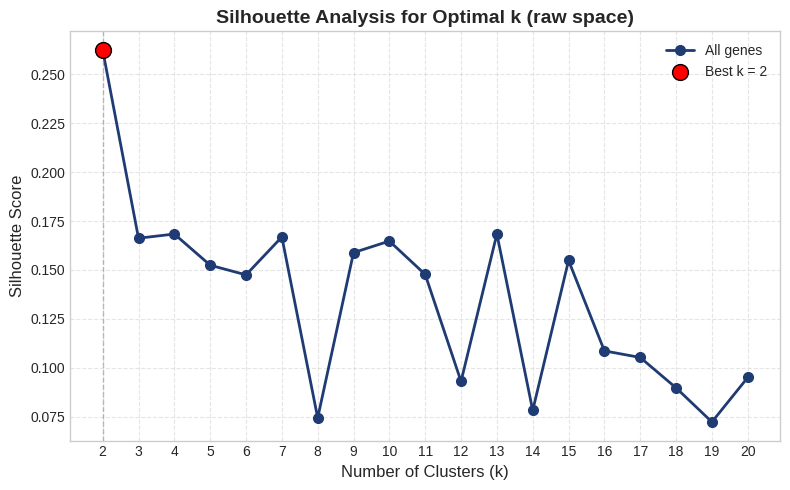

[All genes | raw space] Best k = 2 | Silhouette = 0.2625


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Curva silhouette senza standardizzazione/PCA (voluto)
def silhouette_curve_raw(X, max_k=20, seed=42, n_init=25):
    n = X.shape[0]  # samples
    Ks = list(range(2, min(max_k, n-1) + 1))  # evita K >= n
    scores = []
    for k in Ks:
        try:
            km = KMeans(n_clusters=k, random_state=seed, n_init=n_init)
            labels = km.fit_predict(X)
            # silhouette richiede almeno 2 cluster distinti
            if len(np.unique(labels)) < 2:
                scores.append(np.nan)
            else:
                scores.append(silhouette_score(X, labels))
        except Exception:
            scores.append(np.nan)
    return Ks, scores

# Calcola curva (X_hot_T: samples x edges)
K_axis, silhouette_all = silhouette_curve_raw(X_all_T, max_k=20, seed=42, n_init=25)


# --- Plot con la grafica richiesta (blu scuro + punto rosso + vline) ---
arr = np.array(silhouette_all, dtype=float)
mask = ~np.isnan(arr)
ks_valid = np.array(K_axis)[mask]
scores_valid = arr[mask]

# trova il best k sui valori validi
best_idx = int(np.argmax(scores_valid))
best_k = int(ks_valid[best_idx])
best_s = float(scores_valid[best_idx])

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))

# linea blu scuro con marker tondi
ax.plot(ks_valid, scores_valid, marker="o", markersize=7, linewidth=2, color="#1f3b73",
        label="All genes")

# punto migliore rosso con bordo nero
ax.scatter(best_k, best_s, s=130, color="red", edgecolor="black", zorder=5,
           label=f"Best k = {best_k}")

# linea verticale tratteggiata sul best k
ax.axvline(best_k, ls="--", lw=1, color="gray", alpha=0.5)

ax.set_xticks(ks_valid)
ax.set_xlabel("Number of Clusters (k)", fontsize=12)
ax.set_ylabel("Silhouette Score", fontsize=12)
ax.set_title("Silhouette Analysis for Optimal k (raw space)", fontsize=14, weight="bold")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

print(f"[All genes | raw space] Best k = {best_k} | Silhouette = {best_s:.4f}")



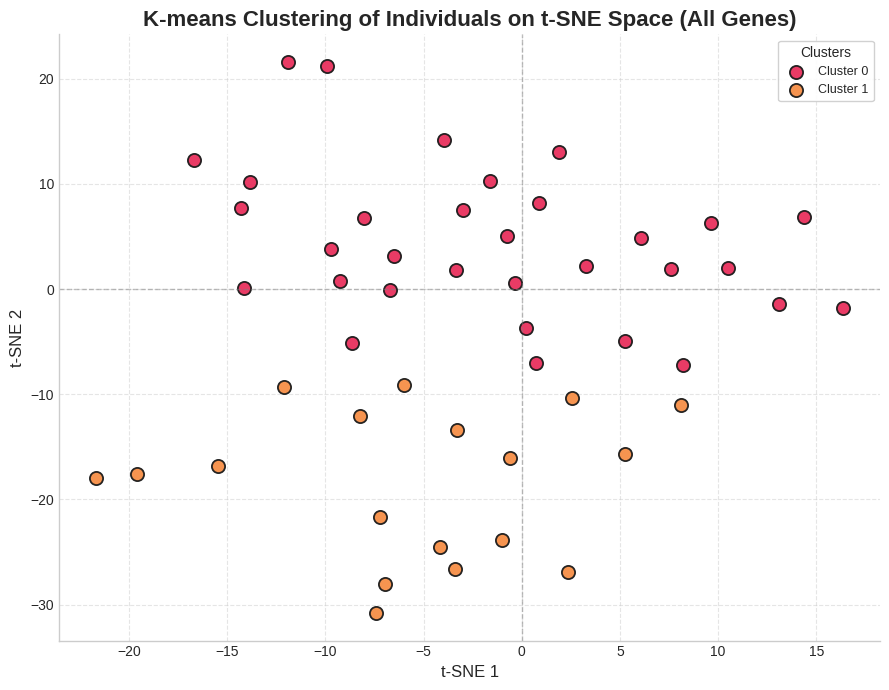

In [ ]:
from matplotlib import colors as mcolors

base_palette = [
    "#e6194b", "#f58231", "#ffe119", "#3cb44b", "#008080", "#46f0f0",
    "#4363d8", "#911eb4", "#f032e6", "#a52a2a", "#7f7f7f", "#bcf60c",
    "#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#8c564b", "#e377c2",
    "#7f7f7f", "#bcbd22"
]
def lighten(hex_color, factor=0.9):
    rgb = np.array(mcolors.to_rgb(hex_color))
    return mcolors.to_hex(1 - factor * (1 - rgb))

edge_color = "#1a1a1a"
face_colors = [lighten(base_palette[i % len(base_palette)], 0.9) for i in range(best_k)]

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))
for k in range(best_k):
    mask = (cluster_labels_all_tsne == k)
    ax.scatter(
        X_tsne[mask, 0], X_tsne[mask, 1],
        s=90, facecolors=face_colors[k], edgecolors=edge_color,
        linewidths=1.3, alpha=0.95, label=f"Cluster {k}"
    )

ax.grid(True, linestyle="--", alpha=0.5)
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.set_title("K-means Clustering of Individuals on t-SNE Space (All Genes)", fontsize=16, weight="bold")
ax.set_xlabel("t-SNE 1", fontsize=12); ax.set_ylabel("t-SNE 2", fontsize=12)
for spine in ["top","right"]: ax.spines[spine].set_visible(False)
leg = ax.legend(frameon=True, title="Clusters", fontsize=9); leg.get_frame().set_alpha(0.9)
plt.tight_layout(); plt.show()


## **Three communities**

In [ ]:
# Per Community 0
sample_cols = [col for col in filtered_df_0.columns if col.startswith('Sample_')]
X_0 = filtered_df_0[sample_cols]
X_0_T = X_0.T  # Trasponi
X_0_T.index.name = 'Sample'

# Per Community 1
sample_cols = [col for col in filtered_df_1.columns if col.startswith('Sample_')]
X_1 = filtered_df_1[sample_cols]
X_1_T = X_1.T
X_1_T.index.name = 'Sample'

# Per Community 2
sample_cols = [col for col in filtered_df_2.columns if col.startswith('Sample_')]
X_2 = filtered_df_2[sample_cols]
X_2_T = X_2.T
X_2_T.index.name = 'Sample'


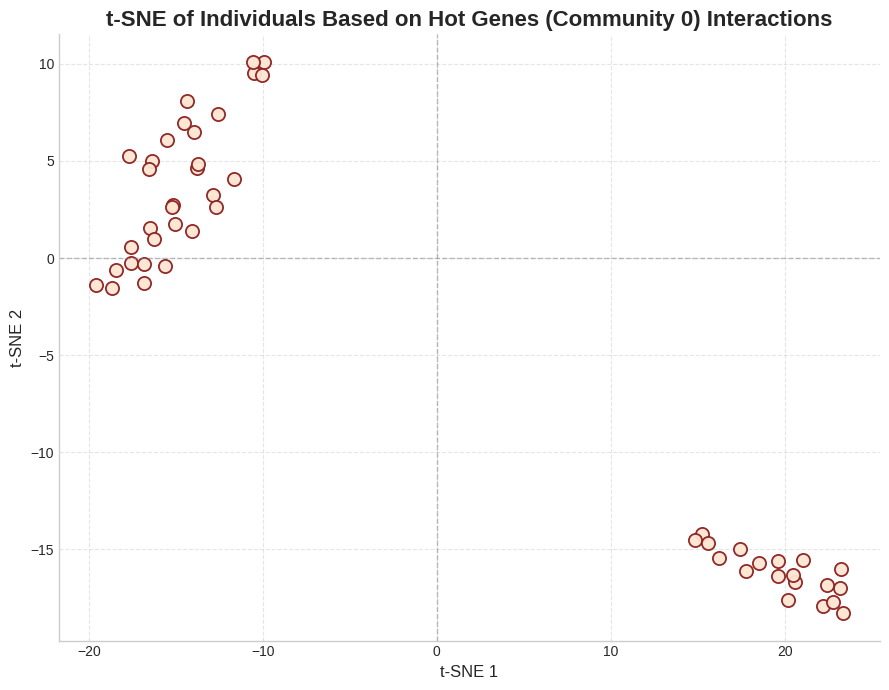

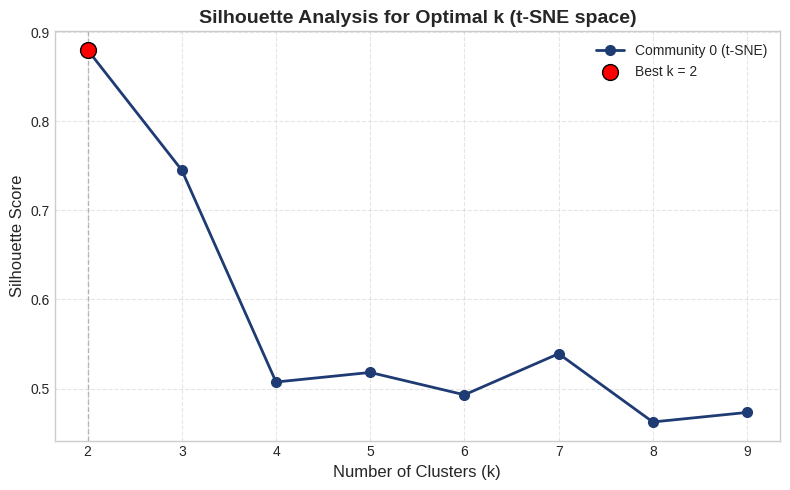

[Community 0 | t-SNE] Best k = 2 | Silhouette = 0.8801
Silhouette (t-SNE): 0.880 | Calinski-Harabasz: 1167.7 | Davies-Bouldin: 0.163


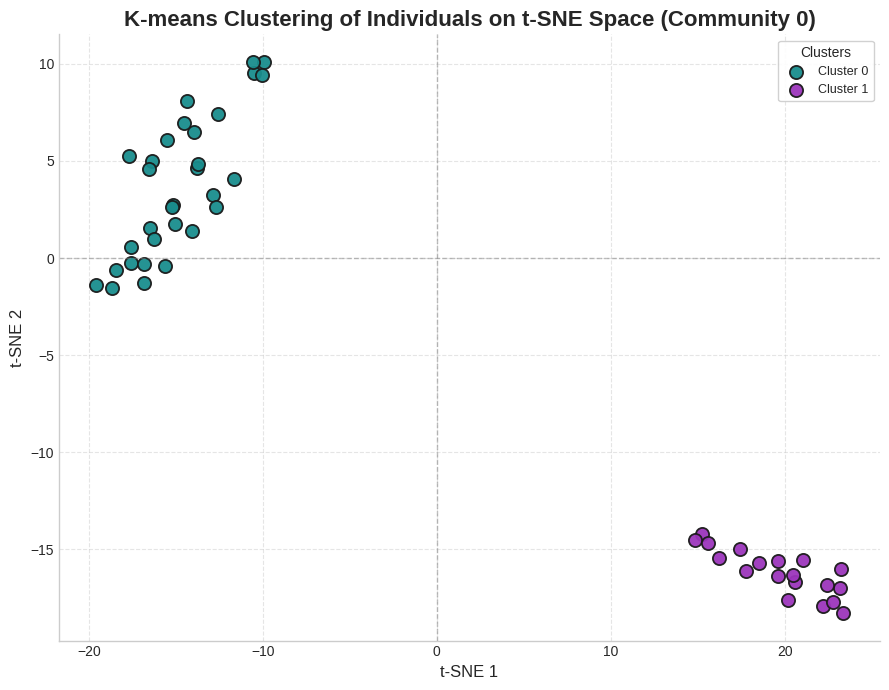

In [ ]:
# t-SNE scatter (Community 0)
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

tsne_0 = TSNE(n_components=2, perplexity=10, random_state=42)
tsne_results_0 = tsne_0.fit_transform(X_0_T)

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))
face_color = "#FDE6D2"; edge_color = "#8B1E1E"
ax.scatter(tsne_results_0[:, 0], tsne_results_0[:, 1],
           s=90, facecolors=face_color, edgecolors=edge_color, linewidths=1.3, alpha=0.95)
ax.grid(True, linestyle="--", alpha=0.5)
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.5); ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.set_title("t-SNE of Individuals Based on Hot Genes (Community 0) Interactions", fontsize=16, weight="bold")
ax.set_xlabel("t-SNE 1", fontsize=12); ax.set_ylabel("t-SNE 2", fontsize=12)
for spine in ["top","right"]: ax.spines[spine].set_visible(False)
plt.tight_layout(); plt.show()

# Silhouette + KMeans nel t-SNE (Community 0)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import numpy as np
from matplotlib import colors as mcolors

X_tsne = tsne_results_0
n_samples = X_tsne.shape[0]

K_range = list(range(2, min(9, n_samples - 1) + 1))
scores, ks_valid = [], []
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    labels = km.fit_predict(X_tsne)
    if len(np.unique(labels)) < 2: continue
    scores.append(silhouette_score(X_tsne, labels)); ks_valid.append(k)

scores = np.array(scores); ks_valid = np.array(ks_valid)
best_idx = int(np.argmax(scores)); best_k = int(ks_valid[best_idx]); best_score = float(scores[best_idx])

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ks_valid, scores, marker="o", markersize=7, linewidth=2, color="#1f3b73", label="Community 0 (t-SNE)")
ax.scatter(best_k, best_score, s=130, color="red", edgecolor="black", zorder=5, label=f"Best k = {best_k}")
ax.axvline(best_k, ls="--", lw=1, color="gray", alpha=0.5)
ax.set_xticks(ks_valid); ax.set_xlabel("Number of Clusters (k)", fontsize=12); ax.set_ylabel("Silhouette Score", fontsize=12)
ax.set_title("Silhouette Analysis for Optimal k (t-SNE space)", fontsize=14, weight="bold")
ax.grid(True, linestyle="--", alpha=0.5); ax.legend(); plt.tight_layout(); plt.show()

print(f"[Community 0 | t-SNE] Best k = {best_k} | Silhouette = {best_score:.4f}")

kmeans_0_tsne = KMeans(n_clusters=best_k, random_state=42, n_init='auto')
cluster_labels_0_tsne = kmeans_0_tsne.fit_predict(X_tsne)

sil = silhouette_score(X_tsne, cluster_labels_0_tsne)
ch  = calinski_harabasz_score(X_tsne, cluster_labels_0_tsne)
db  = davies_bouldin_score(X_tsne, cluster_labels_0_tsne)
print(f"Silhouette (t-SNE): {sil:.3f} | Calinski-Harabasz: {ch:.1f} | Davies-Bouldin: {db:.3f}")

# Plot cluster (Community 0) — FIX: usa cluster_labels_0_tsne nel mask
base_palette = ["#008080", "#911eb4", "#f032e6", "#a52a2a", "#7f7f7f", "#bcf60c",
                "#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#8c564b", "#e377c2"]
def lighten(hex_color, factor=0.9):
    rgb = np.array(mcolors.to_rgb(hex_color)); return mcolors.to_hex(1 - factor * (1 - rgb))

edge_color = "#1a1a1a"
face_colors = [lighten(base_palette[i % len(base_palette)], 0.9) for i in range(best_k)]

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))
for k in range(best_k):
    mask = (cluster_labels_0_tsne == k)   # <-- CORRETTO
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
               s=90, facecolors=face_colors[k], edgecolors=edge_color,
               linewidths=1.3, alpha=0.95, label=f"Cluster {k}")
ax.grid(True, linestyle="--", alpha=0.5)
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.5); ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.set_title("K-means Clustering of Individuals on t-SNE Space (Community 0)", fontsize=16, weight="bold")
ax.set_xlabel("t-SNE 1", fontsize=12); ax.set_ylabel("t-SNE 2", fontsize=12)
for spine in ["top","right"]: ax.spines[spine].set_visible(False)
leg = ax.legend(frameon=True, title="Clusters", fontsize=9); leg.get_frame().set_alpha(0.9)
plt.tight_layout(); plt.show()


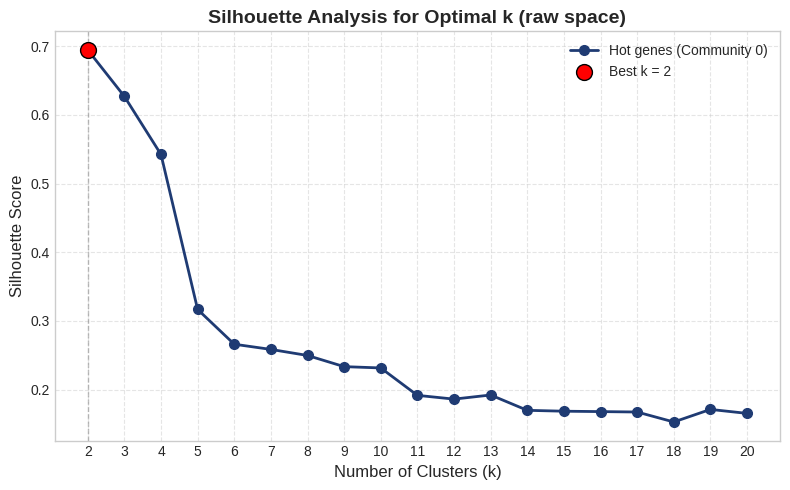

[Hot genes (Community 0) | raw space] Best k = 2 | Silhouette = 0.6946


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Curva silhouette senza standardizzazione/PCA (voluto)
def silhouette_curve_raw(X, max_k=20, seed=42, n_init=25):
    n = X.shape[0]  # samples
    Ks = list(range(2, min(max_k, n-1) + 1))  # evita K >= n
    scores = []
    for k in Ks:
        try:
            km = KMeans(n_clusters=k, random_state=seed, n_init=n_init)
            labels = km.fit_predict(X)
            # silhouette richiede almeno 2 cluster distinti
            if len(np.unique(labels)) < 2:
                scores.append(np.nan)
            else:
                scores.append(silhouette_score(X, labels))
        except Exception:
            scores.append(np.nan)
    return Ks, scores

# Calcola curva (X_hot_T: samples x edges)
K_axis, silhouette_0 = silhouette_curve_raw(X_0_T, max_k=20, seed=42, n_init=25)


# --- Plot con la grafica richiesta (blu scuro + punto rosso + vline) ---
arr = np.array(silhouette_0, dtype=float)
mask = ~np.isnan(arr)
ks_valid = np.array(K_axis)[mask]
scores_valid = arr[mask]

# trova il best k sui valori validi
best_idx = int(np.argmax(scores_valid))
best_k = int(ks_valid[best_idx])
best_s = float(scores_valid[best_idx])

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))

# linea blu scuro con marker tondi
ax.plot(ks_valid, scores_valid, marker="o", markersize=7, linewidth=2, color="#1f3b73",
        label="Hot genes (Community 0)")

# punto migliore rosso con bordo nero
ax.scatter(best_k, best_s, s=130, color="red", edgecolor="black", zorder=5,
           label=f"Best k = {best_k}")

# linea verticale tratteggiata sul best k
ax.axvline(best_k, ls="--", lw=1, color="gray", alpha=0.5)

ax.set_xticks(ks_valid)
ax.set_xlabel("Number of Clusters (k)", fontsize=12)
ax.set_ylabel("Silhouette Score", fontsize=12)
ax.set_title("Silhouette Analysis for Optimal k (raw space)", fontsize=14, weight="bold")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

print(f"[Hot genes (Community 0) | raw space] Best k = {best_k} | Silhouette = {best_s:.4f}")



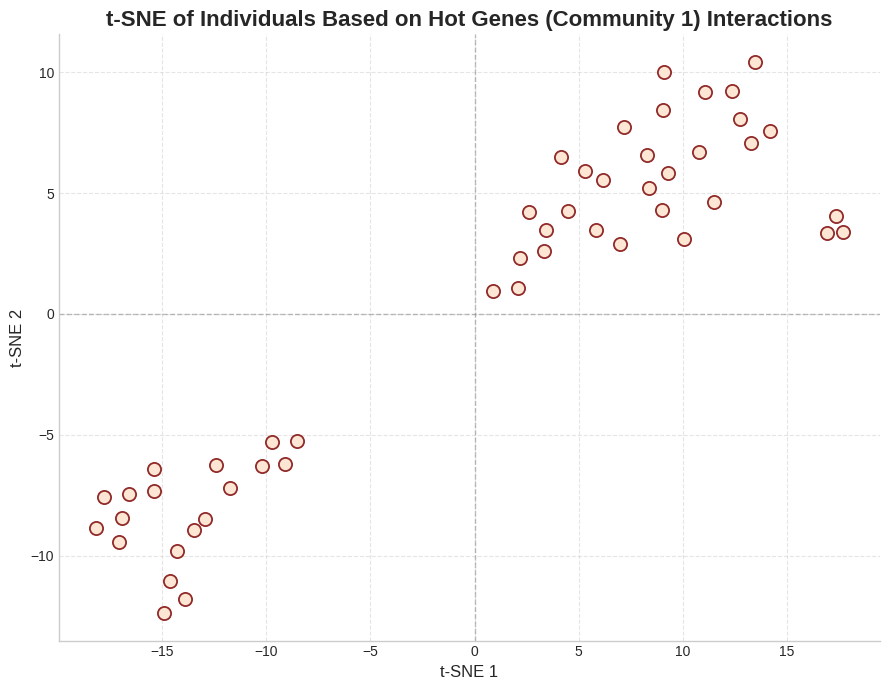

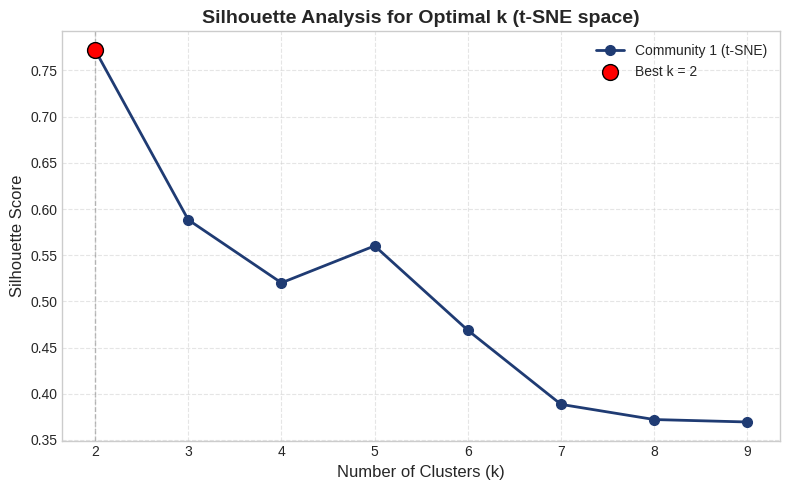

[Community 1 | t-SNE] Best k = 2 | Silhouette = 0.7722
Silhouette (t-SNE): 0.772 | Calinski-Harabasz: 358.2 | Davies-Bouldin: 0.300


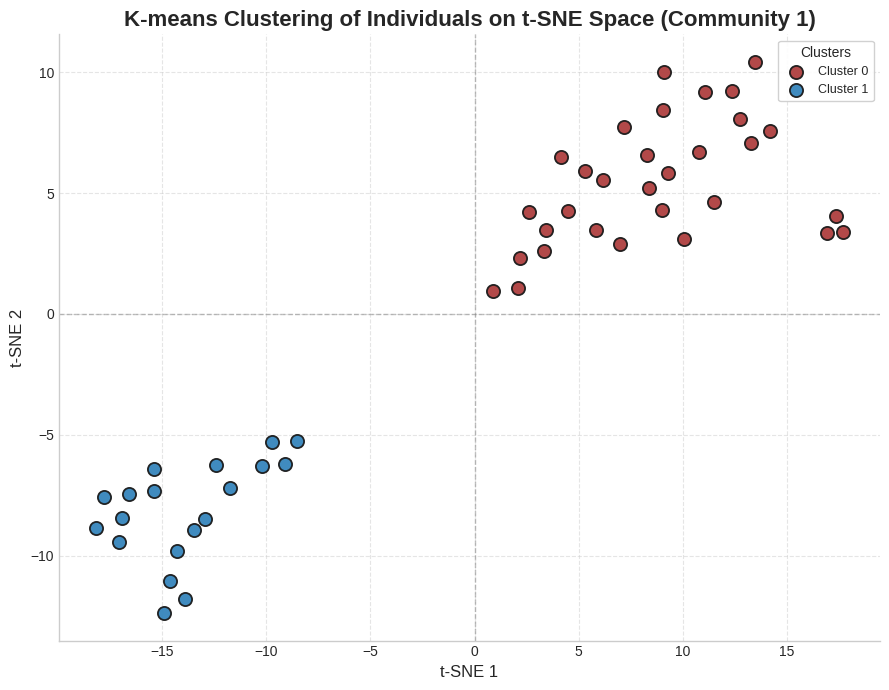

In [ ]:
# t-SNE scatter (Community 1)
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

tsne_1 = TSNE(n_components=2, perplexity=10, random_state=42)
tsne_results_1 = tsne_1.fit_transform(X_1_T)

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))
face_color = "#FDE6D2"; edge_color = "#8B1E1E"
ax.scatter(tsne_results_1[:, 0], tsne_results_1[:, 1],
           s=90, facecolors=face_color, edgecolors=edge_color, linewidths=1.3, alpha=0.95)
ax.grid(True, linestyle="--", alpha=0.5)
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.5); ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.set_title("t-SNE of Individuals Based on Hot Genes (Community 1) Interactions", fontsize=16, weight="bold")
ax.set_xlabel("t-SNE 1", fontsize=12); ax.set_ylabel("t-SNE 2", fontsize=12)
for spine in ["top","right"]: ax.spines[spine].set_visible(False)
plt.tight_layout(); plt.show()

# Silhouette + KMeans nel t-SNE (Community 1)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import numpy as np
from matplotlib import colors as mcolors

X_tsne = tsne_results_1
n_samples = X_tsne.shape[0]
K_range = list(range(2, min(9, n_samples - 1) + 1))
scores, ks_valid = [], []
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    labels = km.fit_predict(X_tsne)
    if len(np.unique(labels)) < 2: continue
    scores.append(silhouette_score(X_tsne, labels)); ks_valid.append(k)

scores = np.array(scores); ks_valid = np.array(ks_valid)
best_idx = int(np.argmax(scores)); best_k = int(ks_valid[best_idx]); best_score = float(scores[best_idx])

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ks_valid, scores, marker="o", markersize=7, linewidth=2, color="#1f3b73", label="Community 1 (t-SNE)")
ax.scatter(best_k, best_score, s=130, color="red", edgecolor="black", zorder=5, label=f"Best k = {best_k}")
ax.axvline(best_k, ls="--", lw=1, color="gray", alpha=0.5)
ax.set_xticks(ks_valid)
ax.set_xlabel("Number of Clusters (k)", fontsize=12); ax.set_ylabel("Silhouette Score", fontsize=12)
ax.set_title("Silhouette Analysis for Optimal k (t-SNE space)", fontsize=14, weight="bold")
ax.grid(True, linestyle="--", alpha=0.5); ax.legend(); plt.tight_layout(); plt.show()

print(f"[Community 1 | t-SNE] Best k = {best_k} | Silhouette = {best_score:.4f}")

kmeans_1_tsne = KMeans(n_clusters=best_k, random_state=42, n_init='auto')
cluster_labels_1_tsne = kmeans_1_tsne.fit_predict(X_tsne)

sil = silhouette_score(X_tsne, cluster_labels_1_tsne)
ch  = calinski_harabasz_score(X_tsne, cluster_labels_1_tsne)
db  = davies_bouldin_score(X_tsne, cluster_labels_1_tsne)
print(f"Silhouette (t-SNE): {sil:.3f} | Calinski-Harabasz: {ch:.1f} | Davies-Bouldin: {db:.3f}")

# Plot cluster (Community 1) — FIX: usa cluster_labels_1_tsne nel mask
base_palette = ["#a52a2a", "#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#8c564b", "#e377c2",
                "#7f7f7f", "#bcbd22"]
def lighten(hex_color, factor=0.9):
    rgb = np.array(mcolors.to_rgb(hex_color)); return mcolors.to_hex(1 - factor * (1 - rgb))

edge_color = "#1a1a1a"
face_colors = [lighten(base_palette[i % len(base_palette)], 0.9) for i in range(best_k)]

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))
for k in range(best_k):
    mask = (cluster_labels_1_tsne == k)   # <-- CORRETTO
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
               s=90, facecolors=face_colors[k], edgecolors=edge_color,
               linewidths=1.3, alpha=0.95, label=f"Cluster {k}")
ax.grid(True, linestyle="--", alpha=0.5)
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.5); ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.set_title("K-means Clustering of Individuals on t-SNE Space (Community 1)", fontsize=16, weight="bold")
ax.set_xlabel("t-SNE 1", fontsize=12); ax.set_ylabel("t-SNE 2", fontsize=12)
for spine in ["top","right"]: ax.spines[spine].set_visible(False)
leg = ax.legend(frameon=True, title="Clusters", fontsize=9); leg.get_frame().set_alpha(0.9)
plt.tight_layout(); plt.show()


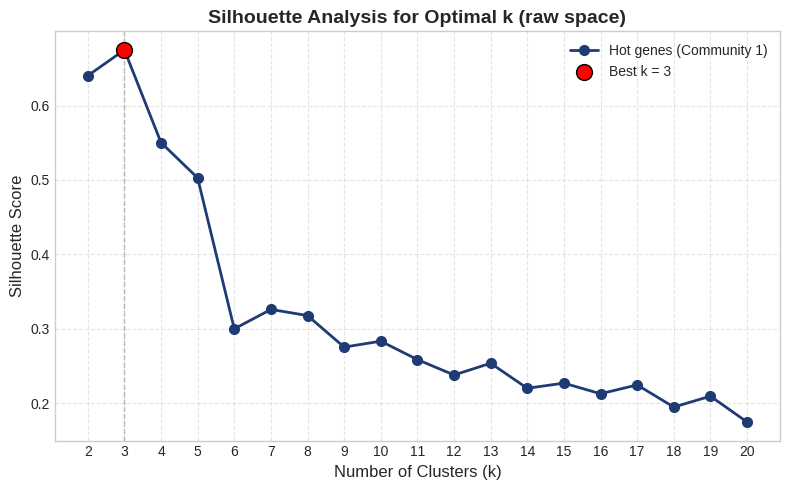

[Hot genes (Community 1) | raw space] Best k = 3 | Silhouette = 0.6747


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Curva silhouette senza standardizzazione/PCA (voluto)
def silhouette_curve_raw(X, max_k=20, seed=42, n_init=25):
    n = X.shape[0]  # samples
    Ks = list(range(2, min(max_k, n-1) + 1))  # evita K >= n
    scores = []
    for k in Ks:
        try:
            km = KMeans(n_clusters=k, random_state=seed, n_init=n_init)
            labels = km.fit_predict(X)
            # silhouette richiede almeno 2 cluster distinti
            if len(np.unique(labels)) < 2:
                scores.append(np.nan)
            else:
                scores.append(silhouette_score(X, labels))
        except Exception:
            scores.append(np.nan)
    return Ks, scores

# Calcola curva (X_hot_T: samples x edges)
K_axis, silhouette_1 = silhouette_curve_raw(X_1_T, max_k=20, seed=42, n_init=25)


# --- Plot con la grafica richiesta (blu scuro + punto rosso + vline) ---
arr = np.array(silhouette_1, dtype=float)
mask = ~np.isnan(arr)
ks_valid = np.array(K_axis)[mask]
scores_valid = arr[mask]

# trova il best k sui valori validi
best_idx = int(np.argmax(scores_valid))
best_k = int(ks_valid[best_idx])
best_s = float(scores_valid[best_idx])

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))

# linea blu scuro con marker tondi
ax.plot(ks_valid, scores_valid, marker="o", markersize=7, linewidth=2, color="#1f3b73",
        label="Hot genes (Community 1)")

# punto migliore rosso con bordo nero
ax.scatter(best_k, best_s, s=130, color="red", edgecolor="black", zorder=5,
           label=f"Best k = {best_k}")

# linea verticale tratteggiata sul best k
ax.axvline(best_k, ls="--", lw=1, color="gray", alpha=0.5)

ax.set_xticks(ks_valid)
ax.set_xlabel("Number of Clusters (k)", fontsize=12)
ax.set_ylabel("Silhouette Score", fontsize=12)
ax.set_title("Silhouette Analysis for Optimal k (raw space)", fontsize=14, weight="bold")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

print(f"[Hot genes (Community 1) | raw space] Best k = {best_k} | Silhouette = {best_s:.4f}")



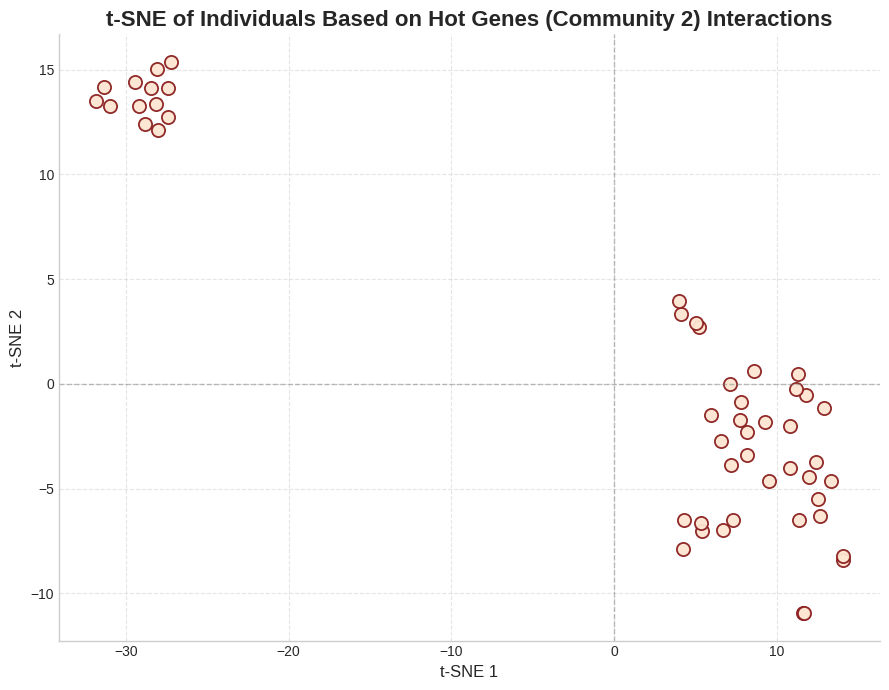

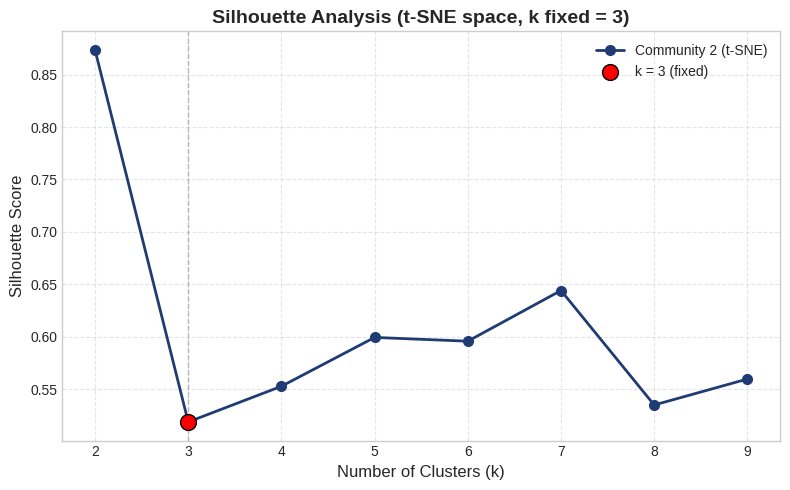

[Community 2 | t-SNE] k (fixed) = 3 | Silhouette = 0.5186
Silhouette (t-SNE): 0.519 | Calinski-Harabasz: 750.4 | Davies-Bouldin: 0.734


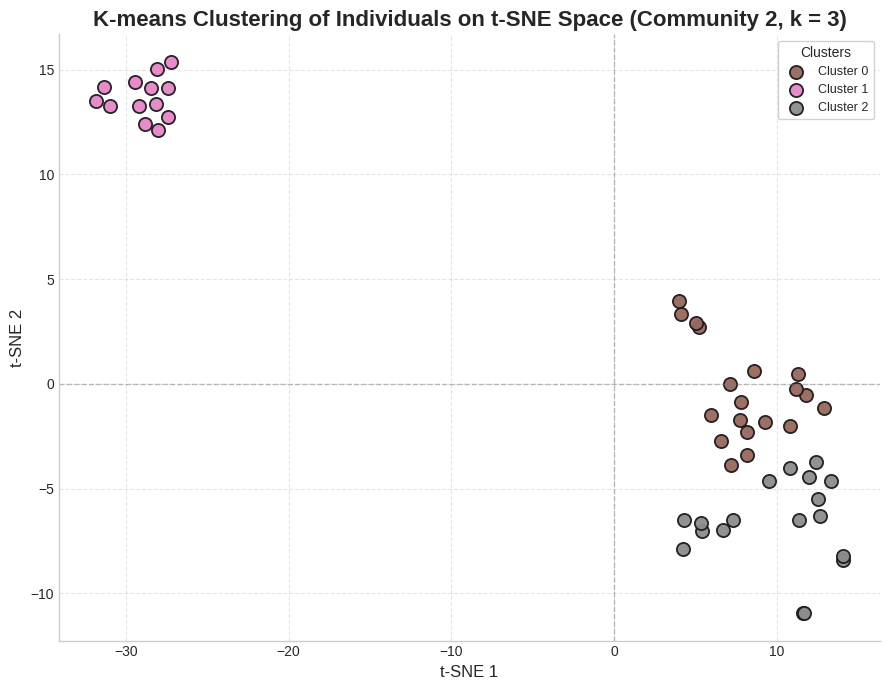

In [ ]:
# === t-SNE scatter (Community 2) ===
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

tsne_2 = TSNE(n_components=2, perplexity=10, random_state=42)
tsne_results_2 = tsne_2.fit_transform(X_2_T)

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))
face_color = "#FDE6D2"; edge_color = "#8B1E1E"
ax.scatter(tsne_results_2[:, 0], tsne_results_2[:, 1],
           s=90, facecolors=face_color, edgecolors=edge_color, linewidths=1.3, alpha=0.95)
ax.grid(True, linestyle="--", alpha=0.5)
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.5); ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.set_title("t-SNE of Individuals Based on Hot Genes (Community 2) Interactions", fontsize=16, weight="bold")
ax.set_xlabel("t-SNE 1", fontsize=12); ax.set_ylabel("t-SNE 2", fontsize=12)
for spine in ["top","right"]: ax.spines[spine].set_visible(False)
plt.tight_layout(); plt.show()

# === Silhouette vs k IN T-SNE space (marker a k=3) ===
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import numpy as np
from matplotlib import colors as mcolors

X_tsne = tsne_results_2
n_samples = X_tsne.shape[0]
K_range = list(range(2, min(9, n_samples - 1) + 1))

scores, ks_valid = [], []
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=25)
    labels = km.fit_predict(X_tsne)
    if len(np.unique(labels)) < 2:
        continue
    scores.append(silhouette_score(X_tsne, labels))
    ks_valid.append(k)

scores = np.array(scores, dtype=float)
ks_valid = np.array(ks_valid, dtype=int)

# k fisso
k_fixed = 3
if k_fixed in ks_valid:
    idx_fixed = int(np.where(ks_valid == k_fixed)[0][0])
else:
    # fallback: K disponibile più vicino a 3
    idx_fixed = int(np.argmin(np.abs(ks_valid - k_fixed)))
k_mark = int(ks_valid[idx_fixed])
score_mark = float(scores[idx_fixed])

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ks_valid, scores, marker="o", markersize=7, linewidth=2, color="#1f3b73", label="Community 2 (t-SNE)")
ax.scatter(k_mark, score_mark, s=130, color="red", edgecolor="black", zorder=5, label=f"k = {k_fixed} (fixed)")
ax.axvline(k_mark, ls="--", lw=1, color="gray", alpha=0.5)
ax.set_xticks(ks_valid)
ax.set_xlabel("Number of Clusters (k)", fontsize=12); ax.set_ylabel("Silhouette Score", fontsize=12)
ax.set_title("Silhouette Analysis (t-SNE space, k fixed = 3)", fontsize=14, weight="bold")
ax.grid(True, linestyle="--", alpha=0.5); ax.legend(); plt.tight_layout(); plt.show()

print(f"[Community 2 | t-SNE] k (fixed) = {k_mark} | Silhouette = {score_mark:.4f}")

# === KMeans definitivo con k=3 ===
kmeans_2_tsne = KMeans(n_clusters=k_fixed, random_state=42, n_init=25)
cluster_labels_2_tsne = kmeans_2_tsne.fit_predict(X_tsne)

sil = silhouette_score(X_tsne, cluster_labels_2_tsne)
ch  = calinski_harabasz_score(X_tsne, cluster_labels_2_tsne)
db  = davies_bouldin_score(X_tsne, cluster_labels_2_tsne)
print(f"Silhouette (t-SNE): {sil:.3f} | Calinski-Harabasz: {ch:.1f} | Davies-Bouldin: {db:.3f}")

# === Plot cluster (Community 2) con k=3 ===
base_palette = ["#8c564b", "#e377c2", "#7f7f7f", "#bcbd22"]
def lighten(hex_color, factor=0.9):
    rgb = np.array(mcolors.to_rgb(hex_color));
    return mcolors.to_hex(1 - factor * (1 - rgb))

edge_color = "#1a1a1a"
face_colors = [lighten(base_palette[i % len(base_palette)], 0.9) for i in range(k_fixed)]

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(9, 7))
for k in range(k_fixed):
    mask = (cluster_labels_2_tsne == k)
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
               s=90, facecolors=face_colors[k], edgecolors=edge_color,
               linewidths=1.3, alpha=0.95, label=f"Cluster {k}")
ax.grid(True, linestyle="--", alpha=0.5)
ax.axhline(0, ls="--", lw=1, c="gray", alpha=0.5); ax.axvline(0, ls="--", lw=1, c="gray", alpha=0.5)
ax.set_title("K-means Clustering of Individuals on t-SNE Space (Community 2, k = 3)", fontsize=16, weight="bold")
ax.set_xlabel("t-SNE 1", fontsize=12); ax.set_ylabel("t-SNE 2", fontsize=12)
for spine in ["top","right"]: ax.spines[spine].set_visible(False)
leg = ax.legend(frameon=True, title="Clusters", fontsize=9); leg.get_frame().set_alpha(0.9)
plt.tight_layout(); plt.show()


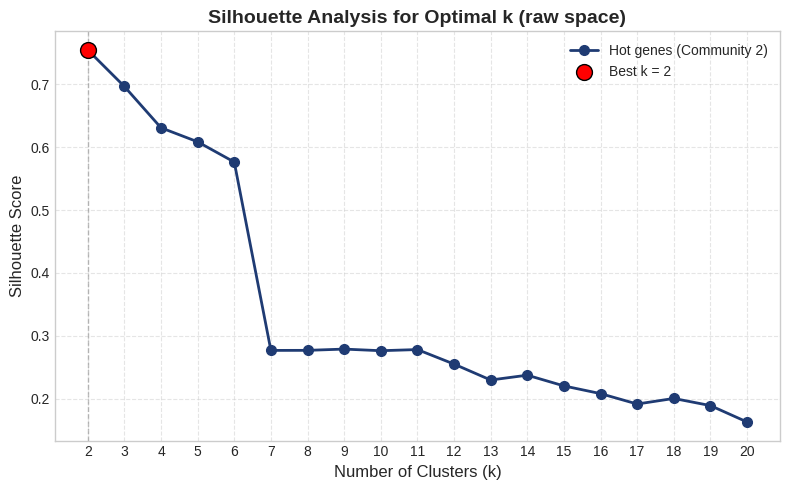

[Hot genes (Community 2) | raw space] Best k = 2 | Silhouette = 0.7550


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Curva silhouette senza standardizzazione/PCA (voluto)
def silhouette_curve_raw(X, max_k=20, seed=42, n_init=25):
    n = X.shape[0]  # samples
    Ks = list(range(2, min(max_k, n-1) + 1))  # evita K >= n
    scores = []
    for k in Ks:
        try:
            km = KMeans(n_clusters=k, random_state=seed, n_init=n_init)
            labels = km.fit_predict(X)
            # silhouette richiede almeno 2 cluster distinti
            if len(np.unique(labels)) < 2:
                scores.append(np.nan)
            else:
                scores.append(silhouette_score(X, labels))
        except Exception:
            scores.append(np.nan)
    return Ks, scores

# Calcola curva (X_hot_T: samples x edges)
K_axis, silhouette_2 = silhouette_curve_raw(X_2_T, max_k=20, seed=42, n_init=25)


# --- Plot con la grafica richiesta (blu scuro + punto rosso + vline) ---
arr = np.array(silhouette_2, dtype=float)
mask = ~np.isnan(arr)
ks_valid = np.array(K_axis)[mask]
scores_valid = arr[mask]

# trova il best k sui valori validi
best_idx = int(np.argmax(scores_valid))
best_k = int(ks_valid[best_idx])
best_s = float(scores_valid[best_idx])

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))

# linea blu scuro con marker tondi
ax.plot(ks_valid, scores_valid, marker="o", markersize=7, linewidth=2, color="#1f3b73",
        label="Hot genes (Community 2)")

# punto migliore rosso con bordo nero
ax.scatter(best_k, best_s, s=130, color="red", edgecolor="black", zorder=5,
           label=f"Best k = {best_k}")

# linea verticale tratteggiata sul best k
ax.axvline(best_k, ls="--", lw=1, color="gray", alpha=0.5)

ax.set_xticks(ks_valid)
ax.set_xlabel("Number of Clusters (k)", fontsize=12)
ax.set_ylabel("Silhouette Score", fontsize=12)
ax.set_title("Silhouette Analysis for Optimal k (raw space)", fontsize=14, weight="bold")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

print(f"[Hot genes (Community 2) | raw space] Best k = {best_k} | Silhouette = {best_s:.4f}")



In [ ]:
import pandas as pd
import plotly.graph_objects as go

# Lista di colori brillanti e distinti (fino a 21)
distinct_colors = [
    "rgb(230, 25, 75)", "rgb(60, 180, 75)", "rgb(255, 225, 25)", "rgb(0, 130, 200)", "rgb(245, 130, 48)",
    "rgb(145, 30, 180)", "rgb(70, 240, 240)", "rgb(240, 50, 230)", "rgb(210, 245, 60)", "rgb(250, 190, 190)",
    "rgb(0, 128, 128)", "rgb(230, 190, 255)", "rgb(170, 110, 40)", "rgb(255, 250, 200)", "rgb(128, 0, 0)",
    "rgb(170, 255, 195)", "rgb(0, 0, 128)", "rgb(128, 128, 0)", "rgb(255, 215, 180)", "rgb(128, 64, 0)",
    "rgb(255, 100, 255)"
]

# Create DataFrame from cluster label arrays
df_clusters = pd.DataFrame({
    'All Genes': cluster_labels_all_tsne,
    'Hot Genes': cluster_labels_hot_tsne,
    'Community 0': cluster_labels_0_tsne,
    'Community 1': cluster_labels_1_tsne,
    'Community 2': cluster_labels_2_tsne
})

# Build labels
label_list = []
label_color = {}
color_index = 0
for col in df_clusters.columns:
    clusters = df_clusters[col].unique()
    for c in clusters:
        label = f"{col}: Cluster {c}"
        label_list.append(label)
        label_color[label] = distinct_colors[color_index % len(distinct_colors)]
        color_index += 1
label_list = list(dict.fromkeys(label_list))  # Remove duplicates

# Map labels to indices
label_to_index = {label: i for i, label in enumerate(label_list)}

# Build source, target, value, link colors
source = []
target = []
value = []
link_colors = []

for i in range(len(df_clusters.columns) - 1):
    col1 = df_clusters.columns[i]
    col2 = df_clusters.columns[i + 1]
    grouped = df_clusters.groupby([col1, col2]).size().reset_index(name='count')
    for _, row in grouped.iterrows():
        src_label = f"{col1}: Cluster {row[col1]}"
        tgt_label = f"{col2}: Cluster {row[col2]}"
        source.append(label_to_index[src_label])
        target.append(label_to_index[tgt_label])
        value.append(row['count'])

        # Create rgba color with transparency from the source node color
        base_rgb = label_color[src_label]
        rgba_color = base_rgb.replace("rgb", "rgba").replace(")", ", 0.4)")
        link_colors.append(rgba_color)

# Sankey diagram
fig = go.Figure(data=[go.Sankey(
    arrangement='snap',
    node=dict(
        pad=15,
        thickness=25,
        line=dict(color="gray", width=0.5),
        label=label_list,
        color=[label_color[label] for label in label_list],
        hovertemplate='Cluster: %{label}<extra></extra>'
    ),
    link=dict(
        source=source,
        target=target,
        value=value,
        color=link_colors,
        hovertemplate='From %{source.label} to %{target.label}<br>Count: %{value}<extra></extra>'
    )
)])

fig.update_layout(
    title_text="Sankey Diagram: Comparison of Clustering Assignments Across Gene Groups",
    font=dict(size=12, color='black'),
    height=700,
    width=1100,
    margin=dict(l=10, r=10, t=40, b=10),
    paper_bgcolor='white',
    plot_bgcolor='white',
    title_x=0.5
)

fig.show()


**Valido valutando comportamento random**

In [ ]:
genes = pd.unique(df[['gene', 'tf']].values.ravel()).tolist()
len(genes)

359

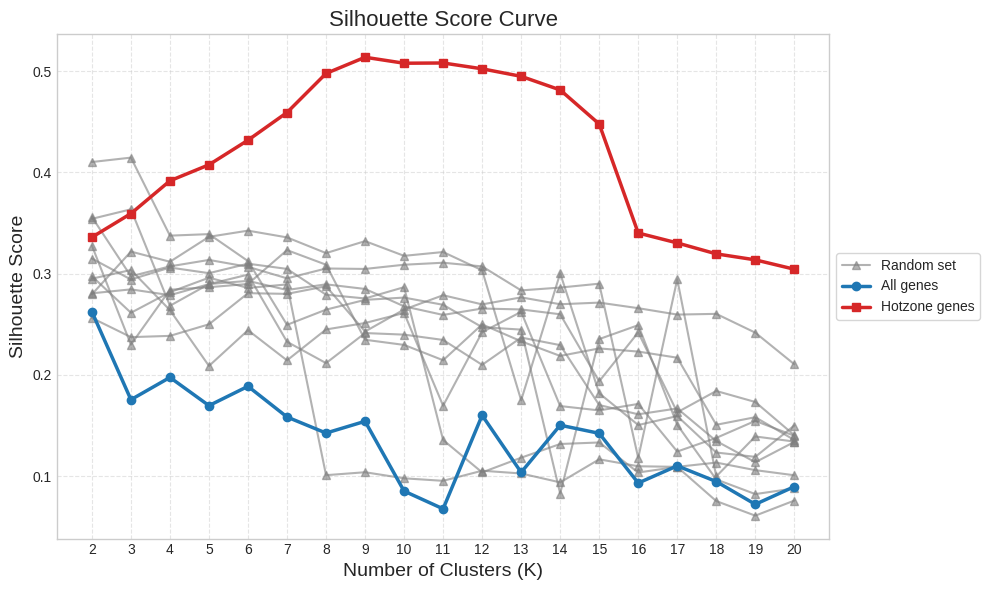

In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ---- definizione richiesta: silhouette senza standardizzazione/PCA ----
def silhouette_curve_raw(X, max_k=20, seed=42, n_init=25):
    n = X.shape[0]  # samples
    Ks = list(range(2, min(max_k, n-1) + 1))  # evita K >= n
    scores = []
    rng = np.random.RandomState(seed)
    for k in Ks:
        try:
            km = KMeans(n_clusters=k, random_state=int(rng.randint(0, 1e9)), n_init=n_init)
            labels = km.fit_predict(X)
            if len(np.unique(labels)) < 2:
                scores.append(np.nan)
            else:
                scores.append(silhouette_score(X, labels))
        except Exception:
            scores.append(np.nan)
    return Ks, scores

# ---- prepara matrici (samples x edges) ----
sample_cols = [col for col in df.columns if col.startswith('Sample_')]

X_all_T = df[sample_cols].values.T
X_hot_T = filtered_df[sample_cols].values.T

# lista geni per i set random (se non l'hai già)
genes = pd.unique(df[['gene', 'tf']].values.ravel()).tolist()

# ---- calcola curve All / Hot con la funzione raw ----
K_all, silhouette_all = silhouette_curve_raw(X_all_T, max_k=20, seed=42, n_init=25)
K_hot, silhouette_hot = silhouette_curve_raw(X_hot_T, max_k=20, seed=43, n_init=25)

# ---- baseline random: stesso schema del tuo codice (n_genes fisso) ----
n_iterations = 10
n_genes = 135
random_curves = []

for i in range(n_iterations):
    random_genes = random.sample(genes, n_genes)
    filtered_random = df[df['tf'].isin(random_genes) & df['gene'].isin(random_genes)]
    if filtered_random.empty:
        continue
    X_rand_T = filtered_random[sample_cols].values.T
    K_r, sil_r = silhouette_curve_raw(X_rand_T, max_k=20, seed=100+i, n_init=25)
    random_curves.append((K_r, sil_r))

# ---- plot (stesso look & feel del tuo) ----
plt.figure(figsize=(10, 6))

# random: tutte le curve (traslucide, una sola label)
for j, (K_r, sil_r) in enumerate(random_curves):
    lbl = "Random set" if j == 0 else None
    plt.plot(K_r, sil_r, linewidth=1.5, marker='^', alpha=0.6, color="#7f7f7f", label=lbl)

# All / Hot
plt.plot(K_all, silhouette_all, marker='o', color='#1f77b4', linewidth=2.5, label="All genes")
plt.plot(K_hot, silhouette_hot, marker='s', color='#d62728', linewidth=2.5, label="Hotzone genes")

# set di tick x: unione dei K usati (così combacia con tutte le curve)
all_Ks = sorted(set(K_all) | set(K_hot) | set(k for K_r,_ in random_curves for k in K_r))
plt.xticks(all_Ks)

# finiture
plt.title('Silhouette Score Curve', fontsize=16)
plt.xlabel('Number of Clusters (K)', fontsize=14)
plt.ylabel('Silhouette Score', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, fontsize=10, loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()


/tmp/ipython-input-4180886430.py:71: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.



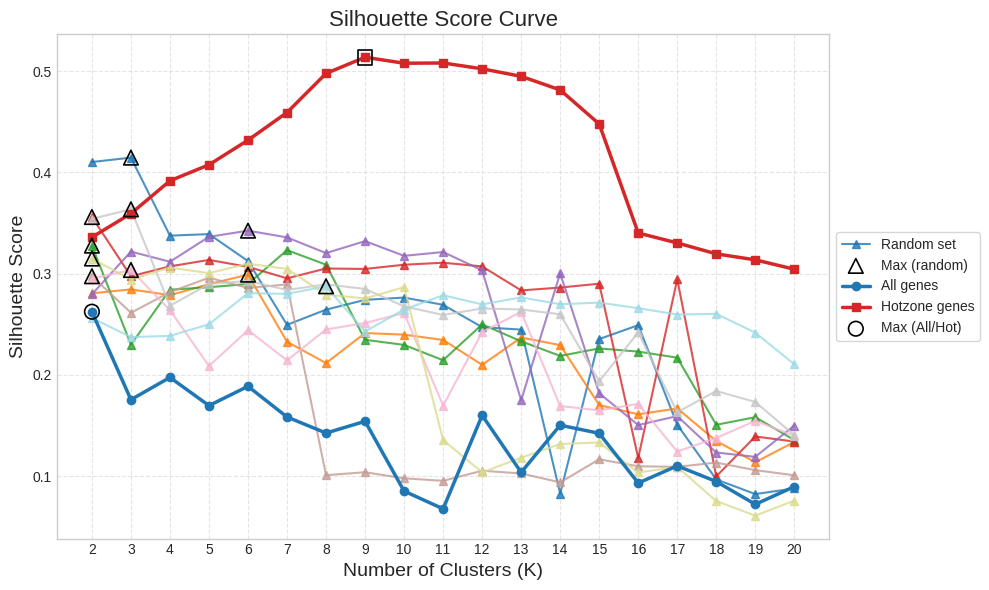

In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ---- definizione richiesta: silhouette senza standardizzazione/PCA ----
def silhouette_curve_raw(X, max_k=20, seed=42, n_init=25):
    n = X.shape[0]  # samples
    Ks = list(range(2, min(max_k, n-1) + 1))  # evita K >= n
    scores = []
    rng = np.random.RandomState(seed)
    for k in Ks:
        try:
            km = KMeans(n_clusters=k, random_state=int(rng.randint(0, 1e9)), n_init=n_init)
            labels = km.fit_predict(X)
            if len(np.unique(labels)) < 2:
                scores.append(np.nan)
            else:
                scores.append(silhouette_score(X, labels))
        except Exception:
            scores.append(np.nan)
    return Ks, scores

# ---- prepara matrici (samples x edges) ----
sample_cols = [col for col in df.columns if col.startswith('Sample_')]

X_all_T = df[sample_cols].values.T
X_hot_T = filtered_df[sample_cols].values.T

# lista geni per i set random (se non l'hai già)
genes = pd.unique(df[['gene', 'tf']].values.ravel()).tolist()

# ---- calcola curve All / Hot con la funzione raw ----
K_all, silhouette_all = silhouette_curve_raw(X_all_T, max_k=20, seed=42, n_init=25)
K_hot, silhouette_hot = silhouette_curve_raw(X_hot_T, max_k=20, seed=43, n_init=25)

# ---- baseline random: stesso schema del tuo codice (n_genes fisso) ----
n_iterations = 10
n_genes = 135
random_curves = []

for i in range(n_iterations):
    random_genes = random.sample(genes, n_genes)
    filtered_random = df[df['tf'].isin(random_genes) & df['gene'].isin(random_genes)]
    if filtered_random.empty:
        continue
    X_rand_T = filtered_random[sample_cols].values.T
    K_r, sil_r = silhouette_curve_raw(X_rand_T, max_k=20, seed=100+i, n_init=25)
    random_curves.append((K_r, sil_r))

# ---- plot (multicolore per i random + massimo evidenziato) ----
plt.figure(figsize=(10, 6))

def mark_max(Ks, scores, label=None, z=5, m='o'):
    # trova il massimo ignorando i NaN
    k_arr = np.array(Ks)
    s_arr = np.array(scores, dtype=float)
    if np.all(np.isnan(s_arr)):
        return None
    idx = np.nanargmax(s_arr)
    x, y = k_arr[idx], s_arr[idx]
    h = plt.scatter([x], [y], s=110, zorder=z, marker=m,
                    edgecolor='k', linewidth=1.2, facecolor='none',
                    label=label)
    return h

# random: tutte le curve con colori diversi (cmap discreta)
n_random = len(random_curves)
cmap = plt.cm.get_cmap('tab20', max(3, min(20, max(n_random, 3))))  # fino a 20 colori ben distinti

random_handles = []
for j, (K_r, sil_r) in enumerate(random_curves):
    color = cmap(j % cmap.N)
    lbl = "Random set" if j == 0 else None
    plt.plot(K_r, sil_r, linewidth=1.5, marker='^', alpha=0.8, color=color, label=lbl)
    # evidenzia massimo (solo un handle in legenda per non affollarla)
    h = mark_max(K_r, sil_r, label="Max (random)" if j == 0 else None, z=6, m='^')
    if h is not None:
        random_handles.append(h)

# All / Hot
line_all, = plt.plot(K_all, silhouette_all, marker='o', color='#1f77b4', linewidth=2.5, label="All genes")
line_hot, = plt.plot(K_hot, silhouette_hot, marker='s', color='#d62728', linewidth=2.5, label="Hotzone genes")

# massimi All / Hot
mark_max(K_all, silhouette_all, label="Max (All/Hot)", z=7, m='o')
mark_max(K_hot, silhouette_hot, z=7, m='s')  # niente label per evitare duplicati

# set di tick x: unione dei K usati (così combacia con tutte le curve)
all_Ks = sorted(set(K_all) | set(K_hot) | set(k for K_r,_ in random_curves for k in K_r))
plt.xticks(all_Ks)

# finiture
plt.title('Silhouette Score Curve', fontsize=16)
plt.xlabel('Number of Clusters (K)', fontsize=14)
plt.ylabel('Silhouette Score', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)

# legenda compatta: una voce per Random set e una per i marker di massimo
plt.legend(frameon=True, fontsize=10, loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()


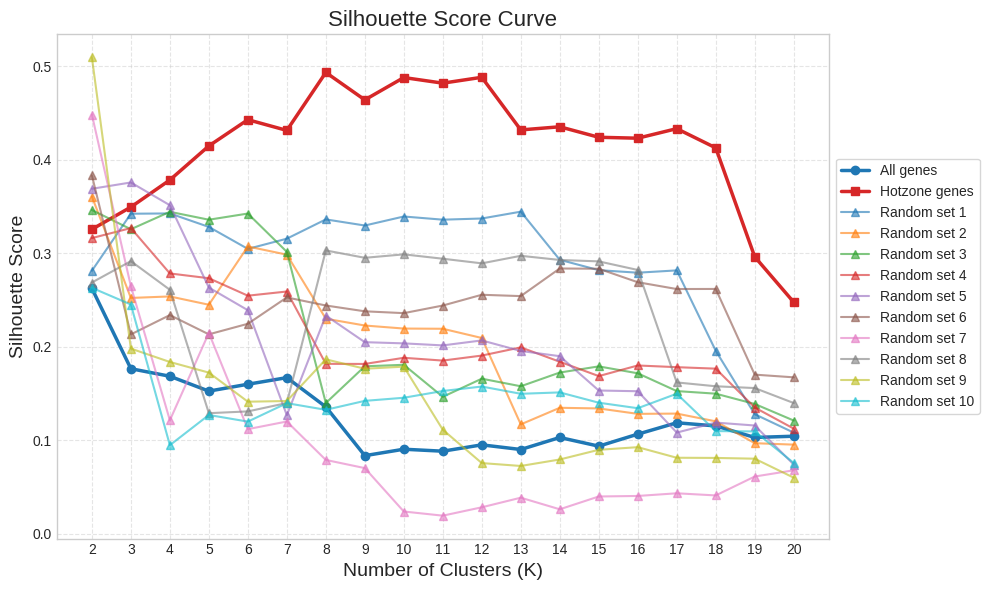

In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Function to compute silhouette scores for a range of K values
def find_best_k_silhouette(X, max_k=20):
    silhouette_scores = []
    for k in range(2, max_k + 1):
        kmeans = KMeans(n_clusters=k, random_state=42)
        labels = kmeans.fit_predict(X)
        score = silhouette_score(X, labels)
        silhouette_scores.append(score)
    return silhouette_scores

# Sample columns
sample_cols = [col for col in df.columns if col.startswith('Sample_')]

# All Genes -> Già sopra
X_all = df[sample_cols].values
X_all_T = X_all.T


# Hotzone Genes -> Già sopra
X_hot = filtered_df[sample_cols].values
X_hot_T = X_hot.T



# Compute silhouette scores for All and Hotzone genes
silhouette_all = find_best_k_silhouette(X_all_T, max_k=20)
silhouette_hotzone = find_best_k_silhouette(X_hot_T, max_k=20)

# Initialize figure
plt.figure(figsize=(10, 6))

# Plot silhouette scores for All and Hotzone genes
plt.plot(range(2, 21), silhouette_all, marker='o', color='#1f77b4', linewidth=2.5, label="All genes")
plt.plot(range(2, 21), silhouette_hotzone, marker='s', color='#d62728', linewidth=2.5, label="Hotzone genes")

# Random gene sampling: 10 iterations
n_iterations = 10
n_genes = 135

for i in range(n_iterations):
    random_genes = random.sample(genes, n_genes)
    filtered_random = df[df['tf'].isin(random_genes) & df['gene'].isin(random_genes)]

    if filtered_random.empty:
        continue

    X_rand = filtered_random[sample_cols].values
    X_rand_T = X_rand.T


    silhouette_rand = find_best_k_silhouette(X_rand_T, max_k=20)
    plt.plot(range(2, 21), silhouette_rand, linewidth=1.5, marker='^', alpha=0.6, label=f"Random set {i+1}")

# Final plot adjustments
plt.title('Silhouette Score Curve', fontsize=16)
plt.xlabel('Number of Clusters (K)', fontsize=14)
plt.ylabel('Silhouette Score', fontsize=14)
plt.xticks(range(2, 21))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, fontsize=10, loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()
